In [1]:
from pathlib import Path
import duckdb


cwd = Path.cwd()
ROOT = cwd.parent if cwd.name == "notebooks" else cwd

CSV_PATH = ROOT / "data" / "raw" / "digikala-comments.csv"
DB_PATH = ROOT / "project.duckdb"

print("ROOT:", ROOT)
print("CSV exists:", CSV_PATH.exists())
print("DuckDB version:", duckdb.__version__)

ROOT: /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer
CSV exists: True
DuckDB version: 2.0.0


# connecting the DuckDB to Database (Dataset)

In [2]:
con = duckdb.connect(str(DB_PATH))
# con.execute("INSTALL ui;")
con.execute("LOAD ui;")
con.execute("CALL start_ui();")

# Prompt for showing first/random 100 records in a table FOR DUCKDB UI

# SELECT * FROM defect_manifest LIMIT 100;
# SELECT * FROM defect_manifest USING SAMPLE 100 ROWS;

Opening in existing browser session.


[1:1:0100/000000.282924:ERROR:content/zygote/zygote_main_linux.cc:197] Failed sending zygote boot message: Broken pipe (32)
[11810:11810:0100/000000.284706:ERROR:content/zygote/zygote_linux.cc:662] write: Broken pipe (32)


# creating project.duckdb (only once)
### loading all the columns as texts

In [3]:
# con.execute(f"""
#     CREATE OR REPLACE TABLE raw AS
#         SELECT row_number() OVER () AS _row_idx, * FROM read_csv(
#         '{CSV_PATH.as_posix()}',
#         header = true,
#         delim = ',',
#         quote = '"',
#         escape = '"',
#         all_varchar = true
#     )
# """)

In [6]:
con.sql("""
    SELECT COUNT(*) AS n_rows,
           COUNT(DISTINCT id) AS n_unique_ids
    FROM raw
""").show()

con.sql("DESCRIBE raw").show()

┌─────────┬──────────────┐
│ n_rows  │ n_unique_ids │
│  int64  │    int64     │
├─────────┼──────────────┤
│ 6156289 │      6153060 │
└─────────┴──────────────┘

┌───────────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│      column_name      │ column_type │  null   │   key   │ default │  extra  │
│        varchar        │   varchar   │ varchar │ varchar │ varchar │ varchar │
├───────────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ id                    │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ title                 │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ body                  │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ created_at            │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ rate                  │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ recommendation_status │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ is_buyer              │ VARCHAR    

# creating two new Tables (run only once):
## defect_manifest
## rule_summary

In [4]:
# con.execute("""
#     CREATE OR REPLACE TABLE defect_manifest (
#         _row_idx BIGINT,
#         id       VARCHAR,
#         rule_id  VARCHAR,
#         field    VARCHAR,
#         action   VARCHAR,
#         evidence VARCHAR
#     )
# """)

# con.execute("""
#     CREATE OR REPLACE TABLE rule_summary (
#         rule_id     VARCHAR,
#         description VARCHAR,
#         action      VARCHAR,
#         n_rows      BIGINT,
#         pct         DOUBLE,
#         reason      VARCHAR
#     )
# """)

In [5]:
con.sql("SELECT _row_idx, id FROM raw ORDER BY _row_idx LIMIT 3").show()
con.sql("SELECT COUNT(*) AS n, MIN(_row_idx) AS lo, MAX(_row_idx) AS hi FROM raw").show()

┌──────────┬──────────┐
│ _row_idx │    id    │
│  int64   │ varchar  │
├──────────┼──────────┤
│        1 │ 53672599 │
│        2 │ 9897229  │
│        3 │ 38074516 │
└──────────┴──────────┘

┌─────────┬───────┬─────────┐
│    n    │  lo   │   hi    │
│  int64  │ int64 │  int64  │
├─────────┼───────┼─────────┤
│ 6156289 │     1 │ 6156289 │
└─────────┴───────┴─────────┘



## creating clean_base (run only once)

In [6]:
# con.execute("""
#     CREATE OR REPLACE TABLE clean_base AS
#     SELECT _row_idx, id, title, body, rate, recommendation_status,
#            product_id, is_buyer, seller_code
#     FROM raw
# """)

# Counting the Missing Values in the columns

In [9]:
cols = ["id", "title", "body", "rate", "recommendation_status",
        "product_id", "is_buyer", "seller_code"]

PLACEHOLDERS = ["null", "nan", "none", "-", "n/a", "na", "undefined"]
ph = ", ".join(f"'{p}'" for p in PLACEHOLDERS)

query = " UNION ALL ".join(f"""
    SELECT '{c}' AS col,
           COUNT(*) FILTER (WHERE {c} IS NULL)                   AS n_null,
           COUNT(*) FILTER (WHERE regexp_matches({c}, '^\\s*$')) AS n_blank,
           COUNT(*) FILTER (WHERE lower(trim({c})) IN ({ph}))    AS n_placeholder,
           COUNT(*) FILTER (WHERE {c} IS NULL)
           + COUNT(*) FILTER (WHERE regexp_matches({c}, '^\\s*$'))
           + COUNT(*) FILTER (WHERE lower(trim({c})) IN ({ph}))  AS n_missing_total
    FROM clean_base
""" for c in cols)

con.sql(query).show()

┌───────────────────────┬────────┬─────────┬───────────────┬─────────────────┐
│          col          │ n_null │ n_blank │ n_placeholder │ n_missing_total │
│        varchar        │ int64  │  int64  │     int64     │      int64      │
├───────────────────────┼────────┼─────────┼───────────────┼─────────────────┤
│ id                    │      0 │       0 │             0 │               0 │
│ title                 │      0 │    1353 │       2865303 │         2866656 │
│ body                  │      0 │       0 │           637 │             637 │
│ rate                  │      0 │       0 │             0 │               0 │
│ recommendation_status │      0 │       0 │        894426 │          894426 │
│ product_id            │      0 │       0 │             0 │               0 │
│ is_buyer              │      0 │       0 │             0 │               0 │
│ seller_code           │      0 │       0 │        302181 │          302181 │
└───────────────────────┴────────┴─────────┴────────

### Placeholder Validation and Missing-Value Inspection

In [10]:
for c in ["title", "body", "recommendation_status", "seller_code"]:
    print(c)
    con.sql(f"""
        SELECT lower(trim({c})) AS value, COUNT(*) AS n
        FROM clean_base
        WHERE lower(trim({c})) IN ({ph}) OR regexp_matches({c}, '^\\s*$')
        GROUP BY 1
        ORDER BY n DESC
    """).show()

con.sql("""
    SELECT recommendation_status, COUNT(*) AS n
    FROM clean_base
    GROUP BY 1
    ORDER BY n DESC
""").show()

title
┌─────────┬─────────┐
│  value  │    n    │
│ varchar │  int64  │
├─────────┼─────────┤
│ nan     │ 2865062 │
│         │    1353 │
│ -       │     241 │
└─────────┴─────────┘

body
┌─────────┬───────┐
│  value  │   n   │
│ varchar │ int64 │
├─────────┼───────┤
│ nan     │   637 │
└─────────┴───────┘

recommendation_status
┌─────────┬────────┐
│  value  │   n    │
│ varchar │ int64  │
├─────────┼────────┤
│ nan     │ 894426 │
└─────────┴────────┘

seller_code
┌─────────┬────────┐
│  value  │   n    │
│ varchar │ int64  │
├─────────┼────────┤
│ nan     │ 302181 │
└─────────┴────────┘

┌───────────────────────┬─────────┐
│ recommendation_status │    n    │
│        varchar        │  int64  │
├───────────────────────┼─────────┤
│ recommended           │ 4162839 │
│ nan                   │  894426 │
│ no_idea               │  594121 │
│ not_recommended       │  504903 │
└───────────────────────┴─────────┘



# Function for Converting All the missing Values to simple 'null'

### Define

In [13]:
con.execute(f"""
    CREATE OR REPLACE MACRO is_missing(x) AS
        lower(trim(x)) IN ({ph}) OR regexp_matches(x, '^\\s*$')
""")

# how it works:
con.sql("""
    SELECT v, is_missing(v) AS got
    FROM (VALUES ('None'), ('  '), (''), ('-'), ('NaN'),
                 ('عالی'), ('نه'), ('nano'), ('خوب نیست')) AS t(v)
""").show()

┌──────────┬─────────┐
│    v     │   got   │
│ varchar  │ boolean │
├──────────┼─────────┤
│ None     │ true    │
│          │ true    │
│          │ true    │
│ -        │ true    │
│ NaN      │ true    │
│ عالی     │ false   │
│ نه       │ false   │
│ nano     │ false   │
│ خوب نیست │ false   │
└──────────┴─────────┘



### Implement (run only once)

In [ ]:
# N_RAW = con.sql("SELECT COUNT(*) FROM raw").fetchall()[0][0]

# for c in cols:
#     n = con.sql(f"SELECT COUNT(*) FROM clean_base WHERE is_missing({c})").fetchall()[0][0]

#     con.execute(
#         "INSERT INTO rule_summary VALUES (?, ?, ?, ?, ?, ?)",
#         [f"MISS_{c}", f"{c}: missing-like text to NULL", "fix",
#          n, 100 * n / N_RAW, "missing values stored as text; standardized"]
#     )

#     con.execute(f"UPDATE clean_base SET {c} = NULL WHERE is_missing({c})")

In [16]:
con.sql("SELECT * FROM rule_summary ORDER BY n_rows DESC").show()

┌────────────────────────────┬──────────────────────────────────────────────────┬─────────┬─────────┬──────────────────────┬─────────────────────────────────────────────┐
│          rule_id           │                   description                    │ action  │ n_rows  │         pct          │                   reason                    │
│          varchar           │                     varchar                      │ varchar │  int64  │        double        │                   varchar                   │
├────────────────────────────┼──────────────────────────────────────────────────┼─────────┼─────────┼──────────────────────┼─────────────────────────────────────────────┤
│ MISS_title                 │ title: missing-like text to NULL                 │ fix     │ 2866656 │    46.56467556997406 │ missing values stored as text; standardized │
│ MISS_recommendation_status │ recommendation_status: missing-like text to NULL │ fix     │  894426 │   14.528655168722587 │ missing values store

## Now again Counting the Missing Values in the columns

In [17]:
cols = ["id", "title", "body", "rate", "recommendation_status",
        "product_id", "is_buyer", "seller_code"]

PLACEHOLDERS = ["null", "nan", "none", "-", "n/a", "na", "undefined"]
ph = ", ".join(f"'{p}'" for p in PLACEHOLDERS)

query = " UNION ALL ".join(f"""
    SELECT '{c}' AS col,
           COUNT(*) FILTER (WHERE {c} IS NULL)                   AS n_null,
           COUNT(*) FILTER (WHERE regexp_matches({c}, '^\\s*$')) AS n_blank,
           COUNT(*) FILTER (WHERE lower(trim({c})) IN ({ph}))    AS n_placeholder,
           COUNT(*) FILTER (WHERE {c} IS NULL)
           + COUNT(*) FILTER (WHERE regexp_matches({c}, '^\\s*$'))
           + COUNT(*) FILTER (WHERE lower(trim({c})) IN ({ph}))  AS n_missing_total
    FROM clean_base
""" for c in cols)

con.sql(query).show()

┌───────────────────────┬─────────┬─────────┬───────────────┬─────────────────┐
│          col          │ n_null  │ n_blank │ n_placeholder │ n_missing_total │
│        varchar        │  int64  │  int64  │     int64     │      int64      │
├───────────────────────┼─────────┼─────────┼───────────────┼─────────────────┤
│ id                    │       0 │       0 │             0 │               0 │
│ title                 │ 2866656 │       0 │             0 │         2866656 │
│ body                  │     637 │       0 │             0 │             637 │
│ rate                  │       0 │       0 │             0 │               0 │
│ recommendation_status │  894426 │       0 │             0 │          894426 │
│ product_id            │       0 │       0 │             0 │               0 │
│ is_buyer              │       0 │       0 │             0 │               0 │
│ seller_code           │  302181 │       0 │             0 │          302181 │
└───────────────────────┴─────────┴─────

# Now cleaning and checking of the 'recommendation_status' column

## assessing the value distribution

In [18]:
con.sql("""
    SELECT recommendation_status AS value,
           length(recommendation_status) AS len,
           COUNT(*) AS n
    FROM clean_base
    GROUP BY 1, 2
    ORDER BY n DESC
""").show()

┌─────────────────┬───────┬─────────┐
│      value      │  len  │    n    │
│     varchar     │ int64 │  int64  │
├─────────────────┼───────┼─────────┤
│ recommended     │    11 │ 4162839 │
│ NULL            │  NULL │  894426 │
│ no_idea         │     7 │  594121 │
│ not_recommended │    15 │  504903 │
└─────────────────┴───────┴─────────┘



### Recommendation_Status Vocabulary Validation

In [20]:
n_unknown = con.sql("""
    SELECT COUNT(*) FROM clean_base
    WHERE recommendation_status IS NOT NULL
      AND recommendation_status NOT IN ('recommended', 'no_idea', 'not_recommended')
""").fetchall()[0][0]

assert n_unknown == 0

# registring in rule_summary table

con.execute(
    "INSERT INTO rule_summary VALUES (?, ?, ?, ?, ?, ?)",
    ["LABEL_rec_vocab", "recommendation_status has only the 3 valid values",
     "check", n_unknown, 100 * n_unknown / N_RAW, "no mapping needed"]
)

### adding null rows to the manifest table (only run once):

In [ ]:
# # Remove earlier rows of this rule, so re-running the cell does not create duplicates
# con.execute("DELETE FROM defect_manifest WHERE rule_id = 'RECOMMENDATION_null'")

# # One manifest row per row whose recommendation_status is NULL (row is kept, action = flag)
# con.execute("""
#     INSERT INTO defect_manifest
#     SELECT _row_idx, id, 'RECOMMENDATION_null', 'recommendation_status', 'flag', recommendation_status
#     FROM clean_base
#     WHERE recommendation_status IS NULL
# """)

# # Control: the number of logged rows must equal the number of NULLs in the column
# n_null_rec = con.sql(
#     "SELECT COUNT(*) FROM clean_base WHERE recommendation_status IS NULL"
# ).fetchall()[0][0]
# n_logged = con.sql(
#     "SELECT COUNT(*) FROM defect_manifest WHERE rule_id = 'RECOMMENDATION_null'"
# ).fetchall()[0][0]
# print(f"recommendation_status NULL rows: {n_null_rec:,}, logged in manifest: {n_logged:,}")
# assert n_logged == n_null_rec, "manifest count does not match NULL count"

recommendation_status NULL rows: 894,426, logged in manifest: 894,426


# Now cleaning and checking of the 'rating' column

### 1- which are not numbers, 2- rate domain, 3- most frequent

In [27]:
# 1) Values that cannot be interpreted as numbers
con.sql("""
    SELECT rate AS value, COUNT(*) AS n
    FROM clean_base
    WHERE TRY_CAST(rate AS DOUBLE) IS NULL
    GROUP BY 1
    ORDER BY n DESC
    LIMIT 30
""").show()

# 2) Minimum and maximum numeric values, and the number of distinct values
con.sql("""
    SELECT MIN(TRY_CAST(rate AS DOUBLE)) AS min_rate,
           MAX(TRY_CAST(rate AS DOUBLE)) AS max_rate,
           COUNT(DISTINCT rate)          AS n_distinct
    FROM clean_base
""").show()

# 3) Most frequent values
con.sql("""
    SELECT rate AS value, COUNT(*) AS n
    FROM clean_base
    GROUP BY 1
    ORDER BY n DESC
    LIMIT 15
""").show()

┌─────────┬───────┐
│  value  │   n   │
│ varchar │ int64 │
└─────────┴───────┘
      0 rows     

┌──────────┬──────────┬────────────┐
│ min_rate │ max_rate │ n_distinct │
│  double  │  double  │   int64    │
├──────────┼──────────┼────────────┤
│      0.0 │   2500.0 │        178 │
└──────────┴──────────┴────────────┘

┌─────────┬─────────┐
│  value  │    n    │
│ varchar │  int64  │
├─────────┼─────────┤
│ 5.0     │ 2398801 │
│ 4.0     │ 1515723 │
│ 3.0     │  958799 │
│ 0.0     │  529098 │
│ 1.0     │  327662 │
│ 2.0     │  198077 │
│ 4.5     │   13479 │
│ 3.5     │   12207 │
│ 4.25    │   11653 │
│ 3.75    │   10045 │
│ 4.2     │    9843 │
│ 3.8     │    8745 │
│ 4.4     │    8675 │
│ 4.75    │    8292 │
│ 4.6     │    8152 │
└─────────┴─────────┘
       15 rows     



### Converting the str to decimal vlaues in rating and Creating rating_bands (only run once)

In [ ]:
# # Shared SQL expression for "the cleaned rate": 2 decimals, or NULL if unusable.
# # Used by the guard, the manifest and the column conversion, so all three agree.
# RATE_CLEAN = """
#     CASE WHEN TRY_CAST(rate AS DECIMAL(10,2)) BETWEEN 0 AND 5
#          THEN TRY_CAST(rate AS DECIMAL(10,2))
#     END
# """

# # 1) Guard: 2-decimal rounding must not change any valid value.
# #    Runs BEFORE the overwrite, while the original text values still exist.
# n_rounded = con.sql(f"""
#     SELECT COUNT(*) FROM clean_base
#     WHERE ({RATE_CLEAN}) IS NOT NULL
#       AND CAST(({RATE_CLEAN}) AS DOUBLE) <> TRY_CAST(rate AS DOUBLE)
# """).fetchall()[0][0]
# assert n_rounded == 0, f"{n_rounded} rate values have more than 2 decimals"

# # 2) Log every unusable rate (the row is kept) in the manifest.
# #    Evidence is the ORIGINAL value, so this must run before the overwrite.
# con.execute(f"""
#     INSERT INTO defect_manifest
#     SELECT _row_idx, id, 'RATE_invalid', 'rate', 'flag', rate
#     FROM clean_base
#     WHERE ({RATE_CLEAN}) IS NULL
# """)
# n_invalid = con.sql(
#     "SELECT COUNT(*) FROM defect_manifest WHERE rule_id = 'RATE_invalid'"
# ).fetchall()[0][0]

# con.execute(
#     "INSERT INTO rule_summary VALUES (?, ?, ?, ?, ?, ?)",
#     ["RATE_invalid", "rate missing, non-numeric or outside 0..5",
#      "flag", n_invalid, 100 * n_invalid / N_RAW,
#      "row kept; only rating_band is invalid for it"]
# )

# # 3) Overwrite rate in place: same name, same position, DECIMAL(10,2).
# #    Unusable values become NULL through the same RATE_CLEAN expression.
# con.execute(f"""
#     ALTER TABLE clean_base
#     ALTER COLUMN rate SET DATA TYPE DECIMAL(10,2)
#     USING ({RATE_CLEAN})
# """)

# # Sanity check: NULLs in rate must match the logged invalid rows exactly.
# n_null = con.sql("SELECT COUNT(*) FROM clean_base WHERE rate IS NULL").fetchall()[0][0]
# assert n_null == n_invalid, "rate NULL count does not match the defect manifest"

# # 4) Add rating_band to clean_base and fill it from the cleaned rate.
# con.execute("ALTER TABLE clean_base ADD COLUMN rating_band VARCHAR")
# con.execute("""
#     UPDATE clean_base
#     SET rating_band = CASE
#         WHEN rate IS NULL THEN NULL
#         WHEN rate < 2.5   THEN 'low'
#         WHEN rate < 4.0   THEN 'medium'
#         ELSE 'high'
#     END
# """)

# # 5) Look at the result. The NULL group is the number of invalid rows.
# con.sql("""
#     SELECT rating_band, COUNT(*) AS n
#     FROM clean_base
#     GROUP BY 1
#     ORDER BY n DESC
# """).show()

# con.sql("""
#     SELECT evidence AS invalid_rate, COUNT(*) AS n
#     FROM defect_manifest
#     WHERE rule_id = 'RATE_invalid'
#     GROUP BY 1
#     ORDER BY n DESC
#     LIMIT 20
# """).show()

┌─────────────┬─────────┐
│ rating_band │    n    │
│   varchar   │  int64  │
├─────────────┼─────────┤
│ high        │ 4004905 │
│ low         │ 1092329 │
│ medium      │ 1059054 │
│ NULL        │       1 │
└─────────────┴─────────┘

┌──────────────┬───────┐
│ invalid_rate │   n   │
│   varchar    │ int64 │
├──────────────┼───────┤
│ NULL         │     1 │
└──────────────┴───────┘



# controlling the Rate and rating_band column and save a report

### for rate Column:

Figures folder: /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/reports/figures
rate range: [0.00, 5.00]
rate column type(s): [('DECIMAL(10,2)', 6156289)]
┌────────────┬─────────┐
│ value_kind │    n    │
│  varchar   │  int64  │
├────────────┼─────────┤
│ number     │ 6156288 │
│ NULL       │       1 │
└────────────┴─────────┘

rate NULL rows: 1 of 6,156,289 (0.00%)
curve min: 0.01%, curve max: 26.63% (must be within 0..100)


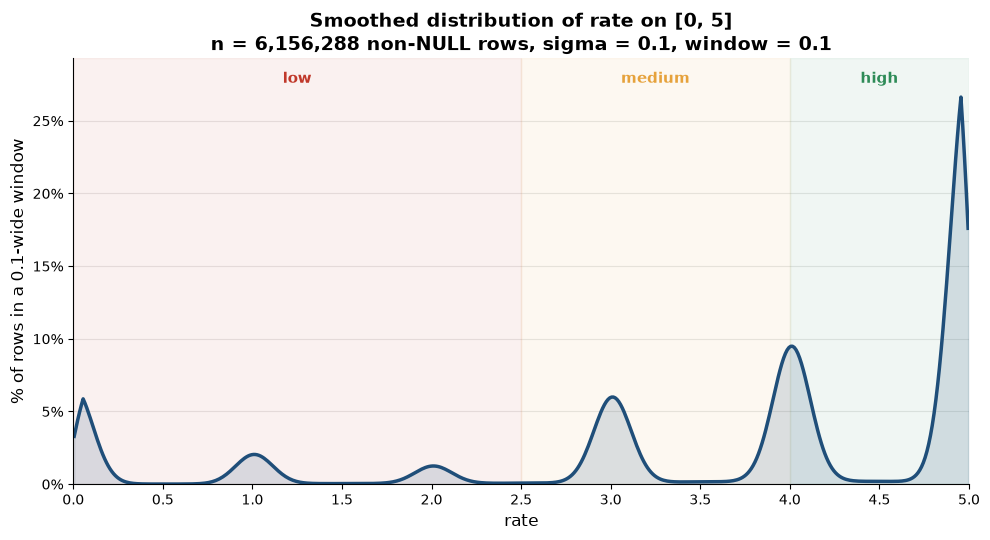

Saved: /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/reports/figures/rate_distribution_curve.png


In [ ]:
# from pathlib import Path

# import numpy as np
# import matplotlib.pyplot as plt
# from matplotlib.ticker import PercentFormatter
# from scipy.ndimage import gaussian_filter1d, uniform_filter1d

# # ---------------- Parameters (edit here) ----------------
# PROJECT_ROOT = None          # None = auto-detect the folder that contains "notebooks/"
# RATE_MIN, RATE_MAX = 0.0, 5.0
# FINE_BIN_WIDTH = 0.01        # histogram bin width in rate units (rate has 2 decimals)
# SMOOTH_SIGMA = 0.10          # Gaussian smoothing width in rate units (larger = smoother)
# RATE_WINDOW = 0.10           # width of the window in which the % of rows is counted
# Y_MIN_PCT = 0.0              # lower limit of the vertical axis, in %
# Y_MAX_PCT = None             # upper limit of the vertical axis, in %; None = automatic
# BAND_EDGES = (2.5, 4.0)      # rating_band thresholds (used for background shading only)
# FIG_NAME = "rate_distribution_curve.png"
# DPI = 200
# BAND_COLORS = {"low": "#c0392b", "medium": "#e6a23c", "high": "#2e8b57"}
# # ---------------------------------------------------------

# # Resolve the project root (the folder that contains notebooks/)
# if PROJECT_ROOT is None:
#     PROJECT_ROOT = next(
#         (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "notebooks").is_dir()),
#         None,
#     )
#     assert PROJECT_ROOT is not None, "Project root not found; set PROJECT_ROOT manually."
# FIG_DIR = Path(PROJECT_ROOT) / "reports" / "figures"
# FIG_DIR.mkdir(parents=True, exist_ok=True)
# print("Figures folder:", FIG_DIR.resolve())

# N_FINE = round((RATE_MAX - RATE_MIN) / FINE_BIN_WIDTH)

# # 1) Range of rate (expected [0.00, 5.00])
# lo, hi = con.sql("SELECT MIN(rate), MAX(rate) FROM clean_base").fetchall()[0]
# print(f"rate range: [{lo}, {hi}]")
# assert float(lo) >= RATE_MIN and float(hi) <= RATE_MAX, "rate is outside the expected range"

# # 2) Data type of the column (expected: one type, DECIMAL)
# type_rows = con.sql("SELECT typeof(rate), COUNT(*) FROM clean_base GROUP BY 1").fetchall()
# print("rate column type(s):", type_rows)
# assert len(type_rows) == 1 and type_rows[0][0].startswith("DECIMAL"), "rate has mixed types"

# # 3) Value kinds: every row is either NULL or a number
# con.sql("""
#     SELECT CASE WHEN rate IS NULL THEN 'NULL' ELSE 'number' END AS value_kind,
#            COUNT(*) AS n
#     FROM clean_base
#     GROUP BY 1
#     ORDER BY n DESC
# """).show()

# # 4) NULL count and share
# n_total, n_null = con.sql(
#     "SELECT COUNT(*), COUNT(*) - COUNT(rate) FROM clean_base"
# ).fetchall()[0]
# print(f"rate NULL rows: {n_null:,} of {n_total:,} ({100 * n_null / n_total:.2f}%)")

# # 5) Histogram on fine bins, computed inside DuckDB.
# #    The epsilon protects FLOOR from float error, e.g. 0.29 / 0.01 = 28.999999999999996.
# hist = con.sql(f"""
#     SELECT CAST(LEAST(
#                FLOOR((CAST(rate AS DOUBLE) - {RATE_MIN}) / {FINE_BIN_WIDTH} + 1e-9),
#                {N_FINE - 1}) AS INTEGER) AS bin_idx,
#            COUNT(*) AS n
#     FROM clean_base
#     WHERE rate BETWEEN {RATE_MIN} AND {RATE_MAX}
#     GROUP BY 1
# """).fetchnumpy()

# counts = np.zeros(N_FINE)
# counts[hist["bin_idx"]] = hist["n"]
# n_valid = counts.sum()

# # 6) Smooth the histogram with a Gaussian kernel.
# #    share[i] = fraction of all rows in fine bin i (the shares sum to 1).
# sigma_bins = SMOOTH_SIGMA / FINE_BIN_WIDTH
# smoothed = gaussian_filter1d(counts, sigma=sigma_bins, mode="reflect")
# smoothed *= n_valid / smoothed.sum()          # keep the total equal to n_valid
# share = smoothed / n_valid

# # 7) At each point, add up the shares inside a window of width RATE_WINDOW centred there.
# #    Each bin is counted at most once, so the value always lies between 0 and 100 %.
# window_bins = max(1, round(RATE_WINDOW / FINE_BIN_WIDTH))
# y_pct = 100 * uniform_filter1d(share, size=window_bins, mode="constant") * window_bins
# x = RATE_MIN + (np.arange(N_FINE) + 0.5) * FINE_BIN_WIDTH

# # Control: every value must lie between 0 and 100
# print(f"curve min: {y_pct.min():.2f}%, curve max: {y_pct.max():.2f}% (must be within 0..100)")
# assert 0 <= y_pct.min() and y_pct.max() <= 100, "curve value outside 0..100"

# fig, ax = plt.subplots(figsize=(10, 5.5))

# # Light background bands for the three rating_band classes
# ax.axvspan(RATE_MIN, BAND_EDGES[0], color=BAND_COLORS["low"], alpha=0.07)
# ax.axvspan(BAND_EDGES[0], BAND_EDGES[1], color=BAND_COLORS["medium"], alpha=0.07)
# ax.axvspan(BAND_EDGES[1], RATE_MAX, color=BAND_COLORS["high"], alpha=0.07)

# # Smooth curve with a light area under it
# ax.plot(x, y_pct, color="#1f4e79", linewidth=2.5)
# ax.fill_between(x, y_pct, color="#1f4e79", alpha=0.15)

# # Vertical axis limits from parameters
# y_top = Y_MAX_PCT if Y_MAX_PCT is not None else y_pct.max() * 1.1
# ax.set_ylim(Y_MIN_PCT, y_top)

# # Class names at the top of each background band
# band_mids = [
#     ("low", (RATE_MIN + BAND_EDGES[0]) / 2),
#     ("medium", (BAND_EDGES[0] + BAND_EDGES[1]) / 2),
#     ("high", (BAND_EDGES[1] + RATE_MAX) / 2),
# ]
# for label, x_mid in band_mids:
#     ax.text(x_mid, y_top * 0.97, label, ha="center", va="top",
#             color=BAND_COLORS[label], fontsize=11, fontweight="bold")

# ax.set_xlim(RATE_MIN, RATE_MAX)
# ax.set_xticks(np.arange(RATE_MIN, RATE_MAX + 1e-9, 0.5))
# ax.set_xlabel("rate", fontsize=12)
# ax.set_ylabel(f"% of rows in a {RATE_WINDOW:g}-wide window", fontsize=12)
# ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
# ax.set_title(
#     f"Smoothed distribution of rate on [{RATE_MIN:g}, {RATE_MAX:g}]\n"
#     f"n = {int(n_valid):,} non-NULL rows, sigma = {SMOOTH_SIGMA:g}, window = {RATE_WINDOW:g}",
#     fontsize=14, fontweight="bold",
# )
# ax.grid(axis="y", alpha=0.3)
# ax.set_axisbelow(True)
# for side in ("top", "right"):
#     ax.spines[side].set_visible(False)
# fig.tight_layout()

# out_curve = FIG_DIR / FIG_NAME
# fig.savefig(out_curve, dpi=DPI, bbox_inches="tight")
# plt.show()
# print("Saved:", out_curve.resolve())

### for rating_band Column

Figures folder: /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/reports/figures
rating_band NULL rows: 1 of 6,156,289 (0.00%)
rating_band column type(s): [('VARCHAR', 6156289)]
   low:    1,092,329  (17.74%)
medium:    1,059,054  (17.20%)
  high:    4,004,905  (65.05%)


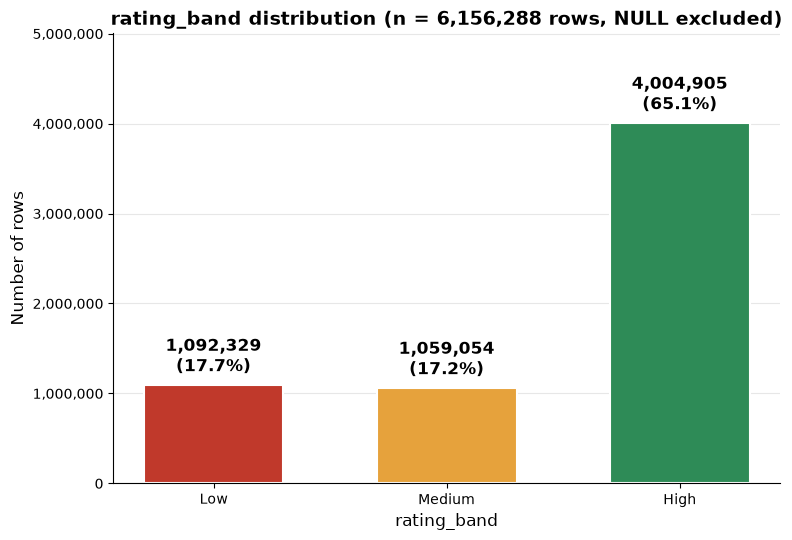

Saved: /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/reports/figures/rating_band_distribution.png


In [ ]:
# from pathlib import Path

# import matplotlib.pyplot as plt
# from matplotlib.ticker import FuncFormatter

# # ---------------- Parameters (edit here) ----------------
# PROJECT_ROOT = None          # None = auto-detect the folder that contains "notebooks/"
# CLASSES = ["low", "medium", "high"]
# BAND_COLORS = {"low": "#c0392b", "medium": "#e6a23c", "high": "#2e8b57"}
# FIG_NAME = "rating_band_distribution.png"
# DPI = 200
# # ---------------------------------------------------------

# # Resolve the project root (the folder that contains notebooks/)
# if PROJECT_ROOT is None:
#     PROJECT_ROOT = next(
#         (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "notebooks").is_dir()),
#         None,
#     )
#     assert PROJECT_ROOT is not None, "Project root not found; set PROJECT_ROOT manually."
# FIG_DIR = Path(PROJECT_ROOT) / "reports" / "figures"
# FIG_DIR.mkdir(parents=True, exist_ok=True)
# print("Figures folder:", FIG_DIR.resolve())

# # 1) NULL rows and data type
# n_total, n_null = con.sql(
#     "SELECT COUNT(*), COUNT(*) - COUNT(rating_band) FROM clean_base"
# ).fetchall()[0]
# print(f"rating_band NULL rows: {n_null:,} of {n_total:,} ({100 * n_null / n_total:.2f}%)")

# type_rows = con.sql("SELECT typeof(rating_band), COUNT(*) FROM clean_base GROUP BY 1").fetchall()
# print("rating_band column type(s):", type_rows)
# assert len(type_rows) == 1 and type_rows[0][0] == "VARCHAR", "rating_band has unexpected type"

# # 2) Count and share of each class (NULL excluded, so shares add up to 100%)
# class_rows = con.sql("""
#     SELECT rating_band, COUNT(*) AS n
#     FROM clean_base
#     WHERE rating_band IS NOT NULL
#     GROUP BY 1
# """).fetchall()
# class_counts = dict(class_rows)
# assert set(class_counts) <= set(CLASSES), f"unexpected labels: {set(class_counts) - set(CLASSES)}"

# ordered = [class_counts.get(c, 0) for c in CLASSES]
# total_valid = sum(ordered)
# percents = [100 * n / total_valid for n in ordered]
# for c, n, p in zip(CLASSES, ordered, percents):
#     print(f"{c:>6}: {n:>12,}  ({p:.2f}%)")

# # 3) Bar chart with count and percentage above each bar
# fig, ax = plt.subplots(figsize=(8, 5.5))
# bars = ax.bar(
#     [c.capitalize() for c in CLASSES], ordered,
#     color=[BAND_COLORS[c] for c in CLASSES],
#     width=0.6, edgecolor="white", linewidth=1.5,
# )
# for bar, n, p in zip(bars, ordered, percents):
#     ax.annotate(
#         f"{n:,}\n({p:.1f}%)",
#         xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
#         xytext=(0, 6), textcoords="offset points",
#         ha="center", va="bottom", fontsize=12, fontweight="bold",
#     )
# ax.set_ylim(0, max(ordered) * 1.25)
# ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
# ax.set_xlabel("rating_band", fontsize=12)
# ax.set_ylabel("Number of rows", fontsize=12)
# ax.set_title(
#     f"rating_band distribution (n = {total_valid:,} rows, NULL excluded)",
#     fontsize=14, fontweight="bold",
# )
# ax.grid(axis="y", alpha=0.3)
# ax.set_axisbelow(True)
# for side in ("top", "right"):
#     ax.spines[side].set_visible(False)
# fig.tight_layout()

# out_bar = FIG_DIR / FIG_NAME
# fig.savefig(out_bar, dpi=DPI, bbox_inches="tight")
# plt.show()
# print("Saved:", out_bar.resolve())

# Normalizing Bodies

### Rules defining

In [19]:
import re
from duckdb.sqltypes import VARCHAR

# Characters are built from code points (no invisible characters in the source)
AR_LETTERS = "\u064a\u0649\u0643"       # Arabic yeh, alef maksura, kaf
FA_LETTERS = "\u06cc\u06cc\u06a9"       # Persian yeh, yeh, keheh

AR_HEH_VARIANTS = "\u06be\u06c1"       # Heh doachashmee, heh goal
FA_HEH = "\u0647\u0647"                 # Persian heh

DIGITS_FROM = (
    "".join(chr(0x0660 + i) for i in range(10))
    + "0123456789"
)
DIGITS_TO = "".join(chr(0x06F0 + i) for i in range(10)) * 2


# ---------------------------------------------------------------------------
# Convert literal Unicode escape sequences into actual ZWNJ characters
# ---------------------------------------------------------------------------
ESCAPED_ZWNJ_RE = re.compile(r"\\u200c", re.IGNORECASE)

def decode_escaped_zwnj(s):
    return ESCAPED_ZWNJ_RE.sub("\u200c", s)


# ---------------------------------------------------------------------------
# Symbol sets (all built from code points)
# ---------------------------------------------------------------------------
# Punctuation marks that are glued to the previous word: . ! ؟ ، ؛ :
P_CHARS = ".!\u061f\u060c\u061b:"

# Emoji ranges (no extra library needed)
EMOJI_CLASS = (
    "\U0001F000-\U0001FAFF"   # emoji blocks (faces, objects, flags, skin tones)
    "\u2600-\u27BF"           # misc symbols and dingbats
    "\u2B00-\u2BFF"           # stars, shapes
    "\u2300-\u23FF"           # clocks, hourglass
    "\uFE0F"                  # emoji variation selector
)

# Characters that are converted to a single standard form
QUOTE_CHARS   = "\u00ab\u00bb\u201c\u201d\u201e\u201f\u2039\u203a\u2033"   # « » “ ” „ ‟ ‹ › ″
DASH_CHARS    = "_\u2014\u2013\u2010\u2011\u2012\u2015\u2212\ufe58\ufe63\uff0d"
PERCENT_CHARS = "\u066a\uff05\ufe6a"                                        # ٪ ％ ﹪

SYMBOL_TABLE = {}
SYMBOL_TABLE.update({ord(c): '"' for c in QUOTE_CHARS})
SYMBOL_TABLE.update({ord(c): "-" for c in DASH_CHARS})
SYMBOL_TABLE.update({ord(c): "%" for c in PERCENT_CHARS})
SYMBOL_TABLE[ord("{")] = "["
SYMBOL_TABLE[ord("}")] = "]"
SYMBOL_TABLE[ord("?")] = "\u061f"      # ? -> ؟
SYMBOL_TABLE[ord(";")] = "\u061b"      # ; -> ؛
SYMBOL_TABLE[ord("\u2026")] = "..."    # … -> ...

LAT_DIGIT = "0-9A-Za-z\u06f0-\u06f9"   # Latin letters/digits and Persian digits

# <text> pair (non-space right after "<" and right before ">") is used as quotes
ANGLE_PAIR_RE = re.compile(r"<(\S(?:[^<>]*\S)?)>")

# 1,000 or 1,000,000 (also Arabic thousands mark) -> digits without separator
THOUSANDS_RE = re.compile(r"(?<![\d,\u066c])\d{1,3}(?:[,\u066c]\d{3})+(?!\d)")

# "," -> "،" unless it sits between two digits / Latin letters (e.g. 1,5 or a,b)
COMMA_RE = re.compile("(?<![" + LAT_DIGIT + "]),|,(?![" + LAT_DIGIT + "])")

def unify_symbols(s):
    # << >> and <text> used as quotation marks
    s = s.replace("<<", '"').replace(">>", '"')
    s = ANGLE_PAIR_RE.sub(r'"\1"', s)
    # quotes, braces, percent, dashes, ? ; ... in one pass
    s = s.translate(SYMBOL_TABLE)
    # thousands separators are removed: ۱,۰۰۰ -> ۱۰۰۰
    s = THOUSANDS_RE.sub(
        lambda m: m.group(0).replace(",", "").replace("\u066c", ""), s
    )
    # remaining commas -> Persian comma
    return COMMA_RE.sub("\u060c", s)


# ---------------------------------------------------------------------------
# Repeated characters: 3+ -> exactly 2
# (digits, spaces, ZWNJ, dots and parentheses are handled by other rules)
# ---------------------------------------------------------------------------
REPEAT_RE = re.compile(r"([^\d\s\u200c.()])\1{2,}")

def collapse_repeats(s):
    return REPEAT_RE.sub(r"\1\1", s)


# ---------------------------------------------------------------------------
# Spacing of punctuation runs, emoji runs, quotes, parentheses and brackets
# ---------------------------------------------------------------------------
# A "run" starts with a punctuation mark or emoji and continues with more
# marks, emoji or parentheses written without spaces (e.g. ":))", "!؟", "😍❤️")
RUN_RE = re.compile(
    "( *)([" + P_CHARS + EMOJI_CLASS + "][" + P_CHARS + EMOJI_CLASS + "()]*)"
)
SYMBOL_RE = re.compile("[" + P_CHARS + EMOJI_CLASS + "]")

# Quotes, parentheses and brackets (a repeated character is one token)
STRUCT_RE = re.compile(r'(\s*)("+|\(+|\)+|\[+|\]+)(\s*)')

# Parentheses inside a run are hidden behind these placeholders,
# so the bracket rule does not touch them (restored at the end)
PAREN_OPEN = "\ue000"
PAREN_CLOSE = "\ue001"

def _is_latin_or_digit(ch):
    return bool(ch) and (
        (ch.isascii() and ch.isalnum()) or "\u06f0" <= ch <= "\u06f9"
    )

def _glue_run(m):
    s = m.string
    spaces, run = m.group(1), m.group(2)
    prev_ch = s[m.start() - 1] if m.start() > 0 else ""
    next_ch = s[m.end()] if m.end() < len(s) else ""

    # 3.5, 12:30, a.com -> a single "." or ":" between digits/Latin chars stays
    if (run in (".", ":") and not spaces
            and _is_latin_or_digit(prev_ch) and _is_latin_or_digit(next_ch)):
        return m.group(0)

    # inside a run, 3+ parentheses -> 2 (emoticons like :)))) )
    run = re.sub(r"\({3,}", "((", run)
    run = re.sub(r"\){3,}", "))", run)
    run = run.replace("(", PAREN_OPEN).replace(")", PAREN_CLOSE)

    # glue the run to the previous word, one space after it if a word follows
    lead = "" if (spaces and prev_ch.isalnum()) else spaces
    tail = " " if next_ch.isalnum() else ""
    return lead + run + tail

def _space_struct(m):
    s = m.string
    token, after = m.group(2), m.group(3)

    # a group made only of parentheses, repeated more than twice -> one
    if token[0] in "()" and len(token) >= 3:
        token = token[0]

    lead = " " if m.start() > 0 else ""

    end = m.end()
    if end >= len(s):
        tail = ""
    elif after:
        tail = " "
    elif SYMBOL_RE.match(s[end]):
        tail = ""            # a mark right after a closing quote/paren stays glued
    else:
        tail = " "
    return lead + token + tail

def space_symbols(s):
    s = re.sub(r" {2,}", " ", s)
    s = RUN_RE.sub(_glue_run, s)
    s = STRUCT_RE.sub(_space_struct, s)
    return s.replace(PAREN_OPEN, "(").replace(PAREN_CLOSE, ")")


# ---------------------------------------------------------------------------
# Remove standalone single Arabic/Persian letters, except Persian conjunction "و"
# ---------------------------------------------------------------------------
SINGLE_LETTER_RE = re.compile(
    r"(?<!\w)[\u0621-\u064A\u066E-\u06D3\u06FA-\u06FC](?!\w)"
)

def remove_single_letters(s):
    return SINGLE_LETTER_RE.sub(
        lambda m: m.group(0) if m.group(0) == "\u0648" else "",
        s
    )


# ---------------------------------------------------------------------------
# Register Python functions in DuckDB
# ---------------------------------------------------------------------------
PY_FUNCTIONS = {
    "decode_escaped_zwnj": decode_escaped_zwnj,
    "unify_symbols": unify_symbols,
    "collapse_repeats": collapse_repeats,
    "space_symbols": space_symbols,
    "remove_single_letters": remove_single_letters,
}

for name, fn in PY_FUNCTIONS.items():
    try:
        con.remove_function(name)
    except Exception:
        pass  # not registered yet
    con.create_function(name, fn, [VARCHAR], VARCHAR)


# ---------------------------------------------------------------------------
# Rules run in this order:
# (rule_id, description, SQL expression over column `txt`)
# ---------------------------------------------------------------------------
RULES = [

    ("NORM_html", "HTML entities decoded, tags removed",
     r"""regexp_replace(
            replace(replace(replace(replace(replace(replace(txt,
                '&nbsp;', ' '), '&amp;', '&'), '&lt;', '<'), '&gt;', '>'),
                '&quot;', '"'), '&zwnj;', chr(8204)),
            '</?[a-zA-Z][^>]*>', ' ', 'g')"""),

    ("NORM_escaped_zwnj", "Literal ZWNJ Unicode escape sequences converted to actual ZWNJ",
     "decode_escaped_zwnj(txt)"),

    ("NORM_invisible", "Zero-width chars, bidi marks, BOM, soft hyphen removed (ZWNJ kept)",
     r"""regexp_replace(txt,
            '[\x{200B}\x{200D}\x{200E}\x{200F}\x{202A}-\x{202E}\x{2060}-\x{2064}\x{2066}-\x{2069}\x{FEFF}\x{00AD}]',
            '', 'g')"""),

    ("NORM_space_ctrl", "Unusual spaces and control chars converted to spaces",
     r"""regexp_replace(txt,
            '[\x{0001}-\x{001F}\x{007F}-\x{009F}\x{00A0}\x{1680}\x{2000}-\x{200A}\x{2028}\x{2029}\x{202F}\x{205F}\x{3000}]',
            ' ', 'g')"""),

    ("NORM_url", "URLs removed",
     r"""regexp_replace(txt,
            '(https?://|www\.)[A-Za-z0-9._~:/?#@!$&*+,;=%()\[\]-]+', ' ', 'gi')"""),

    ("NORM_arabic_letters", "Arabic yeh/kaf variants converted to Persian",
     "translate(txt, '" + AR_LETTERS + "', '" + FA_LETTERS + "')"),

    ("NORM_heh", "Non-standard Arabic/Urdu heh variants converted to Persian heh",
     "translate(txt, '" + AR_HEH_VARIANTS + "', '" + FA_HEH + "')"),

    ("NORM_diacritics", "Diacritics and tatweel removed",
     r"""regexp_replace(txt, '[\x{064B}-\x{065F}\x{0670}\x{0640}]', '', 'g')"""),

    ("NORM_digits", "Arabic-Indic and Latin digits converted to Persian digits",
     "translate(txt, '" + DIGITS_FROM + "', '" + DIGITS_TO + "')"),

    ("NORM_symbols_unify",
     "Quotes, braces, percent, dashes, ? ; , converted to one standard form; thousands separators removed",
     "unify_symbols(txt)"),

    ("NORM_repeats", "Characters repeated 3+ times reduced to 2 (not digits, dots, parentheses)",
     "collapse_repeats(txt)"),

    ("NORM_dots", "Two or more dots become exactly three dots",
     r"""regexp_replace(txt, '\.{2,}', '...', 'g')"""),

    ("NORM_symbol_spacing",
     "Spacing of punctuation/emoji runs, quotes, parentheses and brackets",
     "space_symbols(txt)"),

    ("NORM_single_letters", "Standalone single Arabic/Persian letters removed, except و",
     "remove_single_letters(txt)"),

    ("NORM_spaces", "Repeated spaces and ZWNJs collapsed",
     r"""regexp_replace(
            regexp_replace(txt, ' {2,}', ' ', 'g'),
            '\x{200C}{2,}', chr(8204), 'g')"""),

    ("NORM_trim", "Leading and trailing spaces/ZWNJs removed",
     r"""regexp_replace(txt, '^[ \x{200C}]+|[ \x{200C}]+$', '', 'g')"""),

    ("NORM_empty", "Empty text after cleaning converted to NULL",
     "CASE WHEN txt = '' THEN NULL ELSE txt END"),
]


def run_rules(con, src, dst, log=False):
    """src: table(_row_idx, txt). Result: dst(_row_idx, txt, changed)."""

    con.execute(
        f"CREATE OR REPLACE TABLE {dst} AS SELECT _row_idx, txt FROM {src}"
    )

    n_total = con.sql(
        f"SELECT COUNT(*) FROM {dst}"
    ).fetchall()[0][0]

    for rule_id, desc, expr in RULES:

        con.execute(f"""
            CREATE OR REPLACE TABLE tmp_stage AS
            WITH s AS (
                SELECT
                    _row_idx,
                    txt AS old,
                    {expr} AS new
                FROM {dst}
            )
            SELECT
                _row_idx,
                new AS txt,
                new IS DISTINCT FROM old AS changed
            FROM s
        """)

        n = con.sql(
            "SELECT COUNT(*) FROM tmp_stage WHERE changed"
        ).fetchall()[0][0]

        con.execute(f"DROP TABLE {dst}")
        con.execute(f"ALTER TABLE tmp_stage RENAME TO {dst}")

        if log:
            con.execute("""
                INSERT INTO rule_summary
                VALUES (?, ?, ?, ?, ?, ?)
            """, [
                rule_id,
                desc,
                "fix",
                n,
                100 * n / n_total if n_total else 0,
                "body text normalization; original text stays in raw"
            ])

### example text

In [15]:
tests = [
    "خوب بود<br>ممنون",
    "ببینید https://x.com/a?b=1 عالی بود",
    "خوب بود\nممنون\r\nعالی\tبود",
    "می\u200cشود  خوب   است",
    "كيفيت ممتاز",
    "خـــوب و زیبَا",
    "٥ ستاره و 5 ستاره",
    "عالیییییی و ههههه",
    "1000 و ۱۰۰۰",
    "عالی!!!!!! بد؟؟؟؟",
    "https://only.link/abc",
    "توصیه نمی\u200cکنم نه",
    "nano na",
    "عــــالی",
    "می‌شود",
    "لب ھارو نرم میکنہ و قیمت مناسب",
    "علامت ؟سوال است",
    "می‌تونست به عنوان یه کالای فرهنگی بهتر بسته بندی بشه",

    # Actual ZWNJ: Python converts \u200c into the real character
    "می\u200cتوانست",

    # Literal escape sequence: the raw string preserves the characters \u200C
    r"می\u200Cتونست به عنوان یه کالای فرهنگی بهتر بسته بندی بشه",
    "دوست داشتم هم جالبه هم شیک  بسته بندی هم تمیز بود هم سالم\r\n*سلامی دوبارهه\r\nبرای بار سوم خریدم:))"
]

con.execute("""
    CREATE OR REPLACE TABLE tmp_test_src (
        _row_idx BIGINT,
        txt VARCHAR
    )
""")

con.executemany(
    "INSERT INTO tmp_test_src VALUES (?, ?)",
    list(enumerate(tests, 1))
)

run_rules(con, "tmp_test_src", "tmp_test_out", log=False)

con.sql("""
    SELECT
        s.txt AS before,
        o.txt AS after
    FROM tmp_test_src s
    JOIN tmp_test_out o USING (_row_idx)
    ORDER BY _row_idx
""").show()

┌───────────────────────────────────────────────────────────┬─────────────────────────────────────────────────────┐
│                          before                           │                        after                        │
│                          varchar                          │                       varchar                       │
├───────────────────────────────────────────────────────────┼─────────────────────────────────────────────────────┤
│ خوب بود<br>ممنون                                          │ خوب بود ممنون                                       │
│ ببینید https://x.com/a?b=1 عالی بود                       │ ببینید عالی بود                                     │
│ خوب بود\nممنون\r\nعالی\tبود                               │ خوب بود ممنون عالی بود                              │
│ می‌شود  خوب   است                                          │ می‌شود خوب است                                       │
│ كيفيت ممتاز                                               │ کیفیت مم

### a better HTML view of the examples

In [16]:
import html
from IPython.display import HTML, display

# Invisible characters are replaced by visible orange tags
MARKS = {
    "\n": "⏎",
    "\r": "␍",
    "\t": "⇥",
    "\u200c": "[ZWNJ]",
    "\u00a0": "[NBSP]",
    "\u200b": "[ZWSP]",
}

CELL = "border:1px solid #888; padding:6px 10px;"


def visible(s):
    # Make one value printable as HTML (NULL and invisible chars become visible)
    if s is None:
        return '<span style="color:#888">NULL</span>'

    s = html.escape(s)

    for ch, mark in MARKS.items():
        s = s.replace(
            ch,
            f'<span dir="ltr" style="color:#e8590c">{mark}</span>'
        )

    return s


def show_pairs(rows, headers=("before", "after")):
    # Draw rows as an HTML table with right-aligned text and visible borders
    head = f'<th style="{CELL}">#</th>' + "".join(
        f'<th style="{CELL}">{h}</th>' for h in headers
    )

    body = ""

    for i, row in enumerate(rows, 1):
        cells = "".join(
            f'<td dir="rtl" style="{CELL} text-align:right">{visible(c)}</td>'
            for c in row
        )

        body += f'<tr><td style="{CELL}">{i}</td>{cells}</tr>'

    display(HTML(
        f'<table style="border-collapse:collapse"><tr>{head}</tr>{body}</table>'
    ))


rows = con.sql("""
    SELECT
        s.txt AS before,
        o.txt AS after
    FROM tmp_test_src s
    JOIN tmp_test_out o USING (_row_idx)
    ORDER BY _row_idx
""").fetchall()

show_pairs(rows)

#,before,after
1,خوب بود<br>ممنون,خوب بود ممنون
2,ببینید https://x.com/a?b=1 عالی بود,ببینید عالی بود
3,خوب بود⏎ممنون␍⏎عالی⇥بود,خوب بود ممنون عالی بود
4,می[ZWNJ]شود خوب است,می[ZWNJ]شود خوب است
5,كيفيت ممتاز,کیفیت ممتاز
6,خـــوب و زیبَا,خوب و زیبا
7,٥ ستاره و 5 ستاره,۵ ستاره و ۵ ستاره
8,عالیییییی و ههههه,عالیی و هه
9,1000 و ۱۰۰۰,۱۰۰۰ و ۱۰۰۰
10,عالی!!!!!! بد؟؟؟؟,عالی!! بد؟؟


### more Example

In [ ]:
tests = [
    ":)))))",
    ": ((",
    ": ( !",
    'گفتم: "سلام"',
    'گفتی :"سیب"',
    "خوب....",
    "خوب..",
    "خوب...سلام",
    "1,000 و 3.5 و 12:30 و a.com",
    "سلام ,خوب ;بد ?چرا",
    "{سلام} و [خوب]",
    "گفت «سلام» و “خوب”",
    "(سلام).",
    "خوب)))",
    "عالی😍😍😍😍 بود",
    "😍عالی",
    "قیمت: ۵۰٪ — خوب _ بد",
    "ممنون!!!!!! عالی !",
    "5 < 6 > 4",
]

con.execute("CREATE OR REPLACE TABLE tmp_test_src (_row_idx BIGINT, txt VARCHAR)")
con.executemany("INSERT INTO tmp_test_src VALUES (?, ?)", list(enumerate(tests, 1)))
run_rules(con, "tmp_test_src", "tmp_test_out", log=False)

rows = con.sql("""
    SELECT s.txt AS before, o.txt AS after
    FROM tmp_test_src s JOIN tmp_test_out o USING (_row_idx)
    ORDER BY _row_idx
""").fetchall()

show_pairs(rows)

#,before,after
1,:))))),:))
2,: ((,: ((
3,: ( !,: ( !
4,"گفتم: ""سلام""","گفتم: "" سلام """
5,"گفتی :""سیب""","گفتی: "" سیب """
6,خوب....,خوب...
7,خوب..,خوب...
8,خوب...سلام,خوب... سلام
9,"1,000 و 3.5 و 12:30 و a.com",۱۰۰۰ و ۳.۵ و ۱۲:۳۰ و a.com
10,"سلام ,خوب ;بد ?چرا",سلام، خوب؛ بد؟ چرا


### Implementing on Clean_base and adding a 'body_norm' column

In [21]:
# Total number of rows before normalization
N_ROWS = con.sql(
    "SELECT COUNT(*) FROM clean_base"
).fetchall()[0][0]

# Remove previous normalization logs
con.execute("""
    DELETE FROM rule_summary
    WHERE rule_id LIKE 'NORM_%'
""")

# Remove previous normalized column
con.execute("""
    ALTER TABLE clean_base
    DROP COLUMN IF EXISTS body_norm
""")

# Create a fresh source table
con.execute("""
    CREATE OR REPLACE TABLE tmp_body_src AS
    SELECT _row_idx, body AS txt
    FROM clean_base
""")

# Run all normalization rules
run_rules(con, "tmp_body_src", "tmp_body", log=True)

# Create a fresh normalized column
con.execute("""
    ALTER TABLE clean_base
    ADD COLUMN body_norm VARCHAR
""")

# Store normalized text using the original row index
con.execute("""
    UPDATE clean_base
    SET body_norm = t.txt
    FROM tmp_body t
    WHERE clean_base._row_idx = t._row_idx
""")

# Verify row count
assert (
    con.sql("SELECT COUNT(*) FROM clean_base").fetchall()[0][0]
    == N_ROWS
)

# Results: rows changed by each rule
con.sql("""
    SELECT
        rule_id,
        n_rows,
        round(pct, 3) AS pct
    FROM rule_summary
    WHERE rule_id LIKE 'NORM_%'
    ORDER BY rule_id
""").show()

# NULL bodies before and after
con.sql("""
    SELECT
        COUNT(*) FILTER (WHERE body IS NULL) AS null_before,
        COUNT(*) FILTER (WHERE body_norm IS NULL) AS null_after
    FROM clean_base
""").show()

# 10 changed examples
rows = con.sql("""
    SELECT
        left(body, 100) AS before,
        left(body_norm, 100) AS after
    FROM clean_base
    WHERE body IS DISTINCT FROM body_norm
    ORDER BY hash(_row_idx)
    LIMIT 10
""").fetchall()

show_pairs(rows)

┌─────────────────────┬─────────┬────────┐
│       rule_id       │ n_rows  │  pct   │
│       varchar       │  int64  │ double │
├─────────────────────┼─────────┼────────┤
│ NORM_arabic_letters │   50340 │  0.818 │
│ NORM_diacritics     │   45574 │   0.74 │
│ NORM_digits         │   97466 │  1.583 │
│ NORM_dots           │   74105 │  1.204 │
│ NORM_empty          │     266 │  0.004 │
│ NORM_escaped_zwnj   │       0 │    0.0 │
│ NORM_heh            │     605 │   0.01 │
│ NORM_html           │    1485 │  0.024 │
│ NORM_invisible      │    1446 │  0.023 │
│ NORM_repeats        │  143300 │  2.328 │
│ NORM_single_letters │  213851 │  3.474 │
│ NORM_space_ctrl     │  567254 │  9.214 │
│ NORM_spaces         │  192149 │  3.121 │
│ NORM_symbol_spacing │ 1052395 │ 17.095 │
│ NORM_symbols_unify  │   14673 │  0.238 │
│ NORM_trim           │  913957 │ 14.846 │
│ NORM_url            │       8 │    0.0 │
└─────────────────────┴─────────┴────────┘
  17 rows                      3 columns

┌───────────

#,before,after
1,مرجوعی برام فرستادم. واقعا چرا رعایت نمی[ZWNJ]کنید تو چسبش مو مونده بود. حالت گرفته بود. نمدونم چرا استفا,مرجوعی برام فرستادم. واقعا چرا رعایت نمی[ZWNJ]کنید تو چسبش مو مونده بود. حالت گرفته بود. نمدونم چرا استفا
2,فوق فوق فوق العاده. اصلا یه چیزیه نگم برات.␍⏎اگر می خوای مثل این مرد جذابا تو فیلما بشی حتما بخونش,فوق فوق فوق العاده. اصلا یه چیزیه نگم برات. اگر می خوای مثل این مرد جذابا تو فیلما بشی حتما بخونش
3,من استفاده میکردم خوب بود چرب نبود و ابرسانی خوبی داشت ولی بعدش که تموم شد دوباره پوستم برگشت بحال ق,من استفاده میکردم خوب بود چرب نبود و ابرسانی خوبی داشت ولی بعدش که تموم شد دوباره پوستم برگشت بحال ق
4,من خیلی خوشم اومد ، با این قیمت فکر نمیکردم این کیفیت باشه ، کلا من سختگیر هستم ولی همه چیزش کامل در,من خیلی خوشم اومد، با این قیمت فکر نمیکردم این کیفیت باشه، کلا من سختگیر هستم ولی همه چیزش کامل درست
5,من همیشه از این مارک خرید میکنم␍⏎و به جرات میگم یکی از جنس های مناسبی در سطح بازار داره.␍⏎سایز کمر م,من همیشه از این مارک خرید میکنم و به جرات میگم یکی از جنس های مناسبی در سطح بازار داره. سایز کمر من
6,قیمت ب صرفه,قیمت صرفه
7,حجمش زیاد بود⏎موهارو هم نرم میکرد,حجمش زیاد بود موهارو هم نرم میکرد
8,با توجه به تحریمها تیغ و شبکه اصلی وارد کشور نمیشه و هر چی که داخل بازاره یا محصول فیک هست یا تیغها,با توجه به تحریمها تیغ و شبکه اصلی وارد کشور نمیشه و هر چی که داخل بازاره یا محصول فیک هست یا تیغهای
9,روان و صاف ، بد نیست,روان و صاف، بد نیست
10,سلام . ممنون از هنرتون . دقیقا همون چیزی بود که در تصویر دیده بودم . بسته بندی عالی و دقیقا به موقع,سلام. ممنون از هنرتون. دقیقا همون چیزی بود که در تصویر دیده بودم. بسته بندی عالی و دقیقا به موقع هم


In [22]:
con.sql("""
    SELECT
        -- rows with the real ZWNJ character
        COUNT(*) FILTER (WHERE contains(body_norm, chr(8204)))                  AS real_zwnj,
        -- rows with the literal text: backslash + u200c (any letter case)
        COUNT(*) FILTER (WHERE contains(lower(body_norm), chr(92) || 'u200c'))  AS literal_text
    FROM clean_base
""").show()

┌───────────┬──────────────┐
│ real_zwnj │ literal_text │
│   int64   │    int64     │
├───────────┼──────────────┤
│    187953 │            0 │
└───────────┴──────────────┘



### Replacing the 'body' with 'body_norm'

In [23]:
# Replace the old body with the normalized one
con.execute("ALTER TABLE clean_base DROP COLUMN body")
con.execute("ALTER TABLE clean_base RENAME COLUMN body_norm TO body")

# Remove the helper tables
con.execute("DROP TABLE tmp_body_src")
con.execute("DROP TABLE tmp_body")

con.sql("DESCRIBE clean_base").show()

┌───────────────────────┬───────────────┬─────────┬─────────┬─────────┬─────────┐
│      column_name      │  column_type  │  null   │   key   │ default │  extra  │
│        varchar        │    varchar    │ varchar │ varchar │ varchar │ varchar │
├───────────────────────┼───────────────┼─────────┼─────────┼─────────┼─────────┤
│ _row_idx              │ BIGINT        │ YES     │ NULL    │ NULL    │ NULL    │
│ id                    │ VARCHAR       │ YES     │ NULL    │ NULL    │ NULL    │
│ title                 │ VARCHAR       │ YES     │ NULL    │ NULL    │ NULL    │
│ rate                  │ DECIMAL(10,2) │ YES     │ NULL    │ NULL    │ NULL    │
│ recommendation_status │ VARCHAR       │ YES     │ NULL    │ NULL    │ NULL    │
│ product_id            │ VARCHAR       │ YES     │ NULL    │ NULL    │ NULL    │
│ is_buyer              │ VARCHAR       │ YES     │ NULL    │ NULL    │ NULL    │
│ seller_code           │ VARCHAR       │ YES     │ NULL    │ NULL    │ NULL    │
│ rating_band   

## newly null-ed rows after normalizing

In [25]:
con.sql("""
    SELECT COUNT(*) AS null_rows
    FROM clean_base
    WHERE body IS NULL
""").show()

┌───────────┐
│ null_rows │
│   int64   │
├───────────┤
│       903 │
└───────────┘



### adding them in Manifest table (run only once)

In [ ]:
# con.execute("""
#     INSERT INTO defect_manifest (
#         _row_idx,
#         id,
#         rule_id,
#         field,
#         action,
#         evidence
#     )
#     SELECT
#         _row_idx,
#         id,
#         'body_null' AS rule_id,
#         'body' AS field,
#         'drop' AS action,
#         '*NULL*' AS evidence
#     FROM clean_base
#     WHERE body IS NULL
# """)

### Dropping the NULLs from Clean_base

In [27]:
con.execute("""
    DELETE FROM clean_base
    WHERE body IS NULL
""")

In [28]:
con.sql("""
    SELECT COUNT(*) AS remaining_null_rows
    FROM clean_base
    WHERE body IS NULL
""").show()

┌─────────────────────┐
│ remaining_null_rows │
│        int64        │
├─────────────────────┤
│                   0 │
└─────────────────────┘



### adding to 'rule_summary' (only run once)

In [ ]:
# con.execute("""
#     INSERT INTO rule_summary (
#         rule_id,
#         description,
#         action,
#         n_rows,
#         pct,
#         reason
#     )
#     VALUES (
#         'MISS_body_norm',
#         'body: missing-like text to NULL',
#         'drop',
#         903,
#         0.000146679,
#         'missing values stored as text; standardized'
#     )
# """)

# Duplicate Records Cleaning

### inspecting (Audit)

In [30]:
# Step 1: find duplicated ids (one row per duplicated id, with its group size)
con.execute("""
    CREATE OR REPLACE TABLE tmp_dup_ids AS
    SELECT id, COUNT(*) AS n_rows
    FROM clean_base
    GROUP BY id
    HAVING COUNT(*) > 1
""")

# Step 2: keep all rows that belong to those ids (for inspection)
con.execute("""
    CREATE OR REPLACE TABLE tmp_dup_rows AS
    SELECT *
    FROM clean_base
    WHERE id IN (SELECT id FROM tmp_dup_ids)
""")

# Step 3: classify every duplicate group by comparing whole rows
con.execute("""
    CREATE OR REPLACE TABLE tmp_dup_groups AS
    WITH variants AS (
        -- identical rows collapse into one; different rows stay separate
        SELECT DISTINCT id, title, body, rate, recommendation_status,
                        product_id, is_buyer, seller_code
        FROM tmp_dup_rows
    ),
    per_id AS (
        SELECT id,
               COUNT(*)                           AS n_variants,
               COUNT(DISTINCT coalesce(body, '')) AS n_bodies
        FROM variants
        GROUP BY id
    )
    SELECT d.id, d.n_rows, p.n_variants, p.n_bodies,
           CASE WHEN p.n_variants = 1 THEN 'identical'
                WHEN p.n_bodies   = 1 THEN 'same_body_other_cols_differ'
                ELSE 'different_body'
           END AS kind
    FROM tmp_dup_ids d
    JOIN per_id p USING (id)
""")

# Summary per kind (extra_rows should add up to 3,229)
con.sql("""
    SELECT kind,
           COUNT(*)           AS n_ids,
           SUM(n_rows - 1)    AS extra_rows,
           SUM(n_rows)        AS n_rows,
    FROM tmp_dup_groups
    GROUP BY 1
    ORDER BY n_ids DESC
""").show()

# Group sizes (2 rows per id, 3 rows per id, ...)
con.sql("""
    SELECT n_rows AS group_size, COUNT(*) AS n_ids
    FROM tmp_dup_groups
    GROUP BY 1
    ORDER BY 1
""").show()

# Look at the rows: non-identical groups first, body shortened to 80 chars
con.sql("""
    SELECT g.kind, r.id, r._row_idx, r.rate, r.recommendation_status,
           r.product_id, left(r.body, 80) AS body_start
    FROM tmp_dup_rows r
    JOIN tmp_dup_groups g USING (id)
    ORDER BY (g.kind = 'identical'), r.id, r._row_idx
    LIMIT 40
""").show()

┌─────────────────────────────┬───────┬────────────┬────────┐
│            kind             │ n_ids │ extra_rows │ n_rows │
│           varchar           │ int64 │   int128   │ int128 │
├─────────────────────────────┼───────┼────────────┼────────┤
│ identical                   │  2886 │       2889 │   5775 │
│ same_body_other_cols_differ │   187 │        187 │    374 │
│ different_body              │   153 │        153 │    306 │
└─────────────────────────────┴───────┴────────────┴────────┘

┌────────────┬───────┐
│ group_size │ n_ids │
│   int64    │ int64 │
├────────────┼───────┤
│          2 │  3223 │
│          3 │     3 │
└────────────┴───────┘

┌─────────────────────────────┬──────────┬──────────┬───────────────┬───────────────────────┬────────────┬──────────────────────────────────────────────────────────────────────────────────┐
│            kind             │    id    │ _row_idx │     rate      │ recommendation_status │ product_id │                                    body_star

### Creating a deletion schedule and executing S1

In [31]:
# Plan table: one row per row we intend to drop (nothing is deleted yet)
con.execute("""
    CREATE OR REPLACE TABLE dup_plan (
        _row_idx     BIGINT,
        id           VARCHAR,
        rule         VARCHAR,
        kept_row_idx BIGINT,   -- the surviving copy (NULL when quarantined)
        evidence     VARCHAR
    )
""")

# S1: identical groups -> keep the copy with the lowest _row_idx
con.execute("""
    INSERT INTO dup_plan
    SELECT r._row_idx, r.id, 'DUP_IDENTICAL',
           MIN(r._row_idx) OVER (PARTITION BY r.id),
           'exact copy of the kept row'
    FROM tmp_dup_rows r
    JOIN tmp_dup_groups g USING (id)
    WHERE g.kind = 'identical'
    QUALIFY r._row_idx > MIN(r._row_idx) OVER (PARTITION BY r.id)
""")

con.sql("SELECT rule, COUNT(*) AS n_rows FROM dup_plan GROUP BY 1").show()
# expected: DUP_IDENTICAL = 2,889

┌───────────────┬────────┐
│     rule      │ n_rows │
│    varchar    │ int64  │
├───────────────┼────────┤
│ DUP_IDENTICAL │   2889 │
└───────────────┴────────┘



```
[S1] kind = identical
  └─ keep 1 row (lowest _row_idx), plan-drop the rest ........ DUP_IDENTICAL
  │
  ▼
[S2] kind = same_body_other_cols_differ
  ├─ 2a same band AND same status ──► keep 1 (has_title, then lowest _row_idx) ... DUP_SAMEBODY_SAMEBAND
  ├─ 2b exactly one row has title ──► keep it, drop no-title rows ............... DUP_SAMEBODY_TITLE
  ├─ 2c exactly one row contradicts status ──► drop it ........................... DUP_SAMEBODY_CONTRADICTION
  └─ 2d still unresolved ──► look by eye ──► QUARANTINE
  ```

### S2 steps 2a, 2b, and 2c

In [32]:
SAME = "same_body_other_cols_differ"

# 2a: same body + same rating_band + same status -> keep one
#     (prefer the copy that has a title, then the lowest _row_idx)
#     rows with NULL rating_band are never treated as "same band"
con.execute(f"""
    INSERT INTO dup_plan
    SELECT _row_idx, id, 'DUP_SAMEBODY_SAMEBAND', kept_idx, evidence
    FROM (
        SELECT r._row_idx, r.id,
               FIRST_VALUE(r._row_idx) OVER w AS kept_idx,
               ROW_NUMBER() OVER w            AS rn,
               'band=' || CAST(r.rating_band AS VARCHAR)
                 || ', status=' || coalesce(r.recommendation_status, 'NULL')
                 || ', rate=' || CAST(r.rate AS VARCHAR) AS evidence
        FROM tmp_dup_rows r
        JOIN tmp_dup_groups g USING (id)
        WHERE g.kind = '{SAME}' AND r.rating_band IS NOT NULL
        WINDOW w AS (PARTITION BY r.id, r.rating_band, r.recommendation_status
                     ORDER BY (r.title IS NULL OR trim(r.title) = ''), r._row_idx)
    )
    WHERE rn > 1
""")

# 2b: if some copies have a title and some do not -> drop the no-title ones
con.execute(f"""
    INSERT INTO dup_plan
    WITH alive AS (
        SELECT r._row_idx, r.id,
               (r.title IS NOT NULL AND trim(r.title) <> '') AS has_title
        FROM tmp_dup_rows r
        JOIN tmp_dup_groups g USING (id)
        WHERE g.kind = '{SAME}'
          AND r._row_idx NOT IN (SELECT _row_idx FROM dup_plan)
    ),
    flagged AS (
        SELECT *,
               BOOL_OR(has_title) OVER (PARTITION BY id)                      AS any_title,
               MIN(_row_idx) FILTER (WHERE has_title) OVER (PARTITION BY id)  AS kept_idx
        FROM alive
    )
    SELECT _row_idx, id, 'DUP_SAMEBODY_NO_TITLE', kept_idx,
           'row has no title, another copy has one'
    FROM flagged
    WHERE NOT has_title AND any_title
""")

# 2c: exactly one remaining copy contradicts its recommendation_status -> drop it
#     contradiction = (recommended AND rate < 2.5) OR (not_recommended AND rate >= 4.0)
con.execute(f"""
    INSERT INTO dup_plan
    WITH alive AS (
        SELECT r._row_idx, r.id, r.rate, r.recommendation_status,
               coalesce(
                   (r.recommendation_status = 'recommended'     AND r.rate < 2.5)
                OR (r.recommendation_status = 'not_recommended' AND r.rate >= 4.0),
                   FALSE) AS contradicts
        FROM tmp_dup_rows r
        JOIN tmp_dup_groups g USING (id)
        WHERE g.kind = '{SAME}'
          AND r._row_idx NOT IN (SELECT _row_idx FROM dup_plan)
    ),
    grp AS (
        SELECT *,
               COUNT(*)                 OVER (PARTITION BY id) AS n_alive,
               SUM(contradicts::INT)    OVER (PARTITION BY id) AS n_contra,
               MIN(_row_idx) FILTER (WHERE NOT contradicts) OVER (PARTITION BY id) AS kept_idx
        FROM alive
    )
    SELECT _row_idx, id, 'DUP_SAMEBODY_CONTRADICTION', kept_idx,
           'status=' || recommendation_status || ', rate=' || CAST(rate AS VARCHAR)
             || ' contradicts the status'
    FROM grp
    WHERE n_alive > 1 AND n_contra = 1 AND contradicts
""")

### 2d (quarantine):
Any id that still has more than one live row will have all its rows deleted.

In [33]:
# 2d: anything still duplicated in the same_body kind -> drop ALL copies
con.execute(f"""
    INSERT INTO dup_plan
    WITH alive AS (
        SELECT r._row_idx, r.id
        FROM tmp_dup_rows r
        JOIN tmp_dup_groups g USING (id)
        WHERE g.kind = '{SAME}'
          AND r._row_idx NOT IN (SELECT _row_idx FROM dup_plan)
    )
    SELECT _row_idx, id, 'DUP_SAMEBODY_QUARANTINE', NULL,
           'unresolved same-body copies: all copies dropped, never used for training'
    FROM alive
    WHERE id IN (SELECT id FROM alive GROUP BY id HAVING COUNT(*) > 1)
""")

con.sql("SELECT rule, COUNT(*) AS n_rows FROM dup_plan GROUP BY 1 ORDER BY 2 DESC").show()

┌────────────────────────────┬────────┐
│            rule            │ n_rows │
│          varchar           │ int64  │
├────────────────────────────┼────────┤
│ DUP_IDENTICAL              │   2889 │
│ DUP_SAMEBODY_SAMEBAND      │    119 │
│ DUP_SAMEBODY_QUARANTINE    │    114 │
│ DUP_SAMEBODY_CONTRADICTION │      6 │
│ DUP_SAMEBODY_NO_TITLE      │      5 │
└────────────────────────────┴────────┘



### Final check, logging, deletion, and re-audit (only once)

In [35]:
# --- Safety checks (must pass before anything is deleted) ---
# 1) no row is planned for dropping twice
n_plan, n_distinct = con.execute(
    "SELECT COUNT(*), COUNT(DISTINCT _row_idx) FROM dup_plan").fetchone()
assert n_plan == n_distinct, "a row appears twice in dup_plan"

# 2) every id keeps at least one row, unless it was quarantined on purpose
bad = con.execute("""
    SELECT r.id
    FROM tmp_dup_rows r
    LEFT JOIN dup_plan p USING (_row_idx)
    GROUP BY r.id
    HAVING COUNT(*) FILTER (WHERE p._row_idx IS NULL) = 0
       AND COUNT(*) FILTER (WHERE p.rule LIKE '%QUARANTINE') = 0
""").fetchall()
assert len(bad) == 0, f"{len(bad)} ids would lose all their rows without quarantine"

# 3) same id but different product_id inside same_body groups (expect 0)
print(con.execute(f"""
    SELECT COUNT(*) FROM (
        SELECT r.id FROM tmp_dup_rows r JOIN tmp_dup_groups g USING (id)
        WHERE g.kind = '{SAME}'
        GROUP BY r.id HAVING COUNT(DISTINCT r.product_id) > 1)
""").fetchone()[0], "same_body ids with different product_id")

# Row count before deletion (also the denominator for pct)
before = con.execute("SELECT COUNT(*) FROM clean_base").fetchone()[0]

# --- Log to defect_manifest (row level) ---
# Re-run safety: remove earlier log rows of the same rules, so a re-run never duplicates them
con.execute("DELETE FROM defect_manifest WHERE rule_id IN (SELECT DISTINCT rule FROM dup_plan)")
con.execute("DELETE FROM rule_summary    WHERE rule_id IN (SELECT DISTINCT rule FROM dup_plan)")

con.execute("""
    INSERT INTO defect_manifest (_row_idx, id, rule_id, field, action, evidence)
    SELECT _row_idx, id, rule, 'id', 'drop',
           'kept_row_idx=' || coalesce(CAST(kept_row_idx AS VARCHAR), 'none (quarantined)')
             || '; ' || evidence
    FROM dup_plan
""")


# --- Log to rule_summary (one row per rule) ---
con.execute(f"""
    INSERT INTO rule_summary (rule_id, description, action, n_rows, pct, reason)
    WITH meta(rule_id, description, reason) AS (
        VALUES
        ('DUP_IDENTICAL',
         'Same id, all compared columns identical: keep the lowest _row_idx',
         'Exact copies carry no extra information'),
        ('DUP_SAMEBODY_SAMEBAND',
         'Same id and body, same rating_band and status: keep one (prefer titled copy)',
         'Copies differ only in minor columns, so the label is unchanged'),
        ('DUP_SAMEBODY_NO_TITLE',
         'Same id and body: drop the copy without title, keep the titled one',
         'Titled copy is the more complete record'),
        ('DUP_SAMEBODY_CONTRADICTION',
         'Same id and body: drop the copy whose rate contradicts recommendation_status',
         'Contradictory copy is likely a placeholder or wrong rate'),
        ('DUP_SAMEBODY_QUARANTINE',
         'Same id and body, unresolved after earlier rules: drop all copies',
         'Label cannot be trusted, so the id is excluded from training')
    )
    SELECT p.rule, m.description, 'drop', COUNT(*),
           COUNT(*) / {before}, m.reason
    FROM dup_plan p
    JOIN meta m ON m.rule_id = p.rule
    GROUP BY p.rule, m.description, m.reason
""")

# --- Delete from clean_base by _row_idx (never by id) ---
con.execute("DELETE FROM clean_base WHERE _row_idx IN (SELECT _row_idx FROM dup_plan)")
after = con.execute("SELECT COUNT(*) FROM clean_base").fetchone()[0]
print(f"clean_base: {before:,} -> {after:,}  (dropped {before - after:,}, planned {n_plan:,})")
assert before - after == n_plan

con.sql("SELECT * FROM rule_summary WHERE rule_id LIKE 'DUP_%' ORDER BY n_rows DESC").show()

0 same_body ids with different product_id
clean_base: 6,155,386 -> 6,152,253  (dropped 3,133, planned 3,133)


ResourceInUseException: Resource In Use Error: connection has an unfinished result from execute(); call complete() or abort(), or fetch until a fetch returns no rows, before other work on this connection, or use a separate connection from cursor()

In [36]:
# Separate cursor, so the unfinished result on `con` does not block us
con.cursor().sql("""
    SELECT * FROM rule_summary
    WHERE rule_id LIKE 'DUP_%'
    ORDER BY n_rows DESC
""").show()

┌────────────────────────────┬──────────────────────────────────────────────────────────────────────────────┬─────────┬────────┬────────────────────────┬────────────────────────────────────────────────────────────────┐
│          rule_id           │                                 description                                  │ action  │ n_rows │          pct           │                             reason                             │
│          varchar           │                                   varchar                                    │ varchar │ int64  │         double         │                            varchar                             │
├────────────────────────────┼──────────────────────────────────────────────────────────────────────────────┼─────────┼────────┼────────────────────────┼────────────────────────────────────────────────────────────────┤
│ DUP_IDENTICAL              │ Same id, all compared columns identical: keep the lowest _row_idx            │ drop    │   28

## Re-audit after some Duplication Droppings

In [37]:
# Step 1: find duplicated ids (one row per duplicated id, with its group size)
con.execute("""
    CREATE OR REPLACE TABLE tmp_dup_ids AS
    SELECT id, COUNT(*) AS n_rows
    FROM clean_base
    GROUP BY id
    HAVING COUNT(*) > 1
""")

# Step 2: keep all rows that belong to those ids (for inspection)
con.execute("""
    CREATE OR REPLACE TABLE tmp_dup_rows AS
    SELECT *
    FROM clean_base
    WHERE id IN (SELECT id FROM tmp_dup_ids)
""")

# Step 3: classify every duplicate group by comparing whole rows
con.execute("""
    CREATE OR REPLACE TABLE tmp_dup_groups AS
    WITH variants AS (
        -- identical rows collapse into one; different rows stay separate
        SELECT DISTINCT id, title, body, rate, recommendation_status,
                        product_id, is_buyer, seller_code
        FROM tmp_dup_rows
    ),
    per_id AS (
        SELECT id,
               COUNT(*)                           AS n_variants,
               COUNT(DISTINCT coalesce(body, '')) AS n_bodies
        FROM variants
        GROUP BY id
    )
    SELECT d.id, d.n_rows, p.n_variants, p.n_bodies,
           CASE WHEN p.n_variants = 1 THEN 'identical'
                WHEN p.n_bodies   = 1 THEN 'same_body_other_cols_differ'
                ELSE 'different_body'
           END AS kind
    FROM tmp_dup_ids d
    JOIN per_id p USING (id)
""")

# Summary per kind (extra_rows should add up to 3,229)
con.sql("""
    SELECT kind,
           COUNT(*)           AS n_ids,
           SUM(n_rows - 1)    AS extra_rows,
           SUM(n_rows)        AS n_rows,
    FROM tmp_dup_groups
    GROUP BY 1
    ORDER BY n_ids DESC
""").show()

# Group sizes (2 rows per id, 3 rows per id, ...)
con.sql("""
    SELECT n_rows AS group_size, COUNT(*) AS n_ids
    FROM tmp_dup_groups
    GROUP BY 1
    ORDER BY 1
""").show()

# Look at the rows: non-identical groups first, body shortened to 80 chars
con.sql("""
    SELECT g.kind, r.id, r._row_idx, r.rate, r.recommendation_status,
           r.product_id, left(r.body, 80) AS body_start
    FROM tmp_dup_rows r
    JOIN tmp_dup_groups g USING (id)
    ORDER BY (g.kind = 'identical'), r.id, r._row_idx
    LIMIT 40
""").show()

┌────────────────┬───────┬────────────┬────────┐
│      kind      │ n_ids │ extra_rows │ n_rows │
│    varchar     │ int64 │   int128   │ int128 │
├────────────────┼───────┼────────────┼────────┤
│ different_body │   153 │        153 │    306 │
└────────────────┴───────┴────────────┴────────┘

┌────────────┬───────┐
│ group_size │ n_ids │
│   int64    │ int64 │
├────────────┼───────┤
│          2 │   153 │
└────────────┴───────┘

┌────────────────┬──────────┬──────────┬───────────────┬───────────────────────┬────────────┬──────────────────────────────────────────────────────────────────────────────────┐
│      kind      │    id    │ _row_idx │     rate      │ recommendation_status │ product_id │                                    body_start                                    │
│    varchar     │ varchar  │  int64   │ decimal(10,2) │        varchar        │  varchar   │                                     varchar                                      │
├────────────────┼──────────┼──────

### Decided to exclude all the left duplicate records, scince all of them are 'different_body' type

In [38]:
RULE = "DUP_DIFFBODY_QUARANTINE"

# Plan table for S3: all copies of every remaining duplicated id
con.execute("""
    CREATE OR REPLACE TABLE dup_plan_s3 AS
    SELECT r._row_idx, r.id, CAST('DUP_DIFFBODY_QUARANTINE' AS VARCHAR) AS rule,
           CAST(NULL AS BIGINT) AS kept_row_idx,
           'edited copies (body differs): all copies dropped; rate=' || CAST(r.rate AS VARCHAR)
             || ', status=' || coalesce(r.recommendation_status, 'NULL') AS evidence
    FROM tmp_dup_rows r
    JOIN tmp_dup_groups g USING (id)
    WHERE g.kind = 'different_body'
""")

# --- Safety checks ---
n_s3, n_distinct_s3, n_ids_s3 = con.execute(
    "SELECT COUNT(*), COUNT(DISTINCT _row_idx), COUNT(DISTINCT id) FROM dup_plan_s3").fetchall()[0]
print(f"S3 plan: {n_s3} rows, {n_ids_s3} ids (expected 306 rows, 153 ids)")
assert n_s3 == n_distinct_s3 == 306 and n_ids_s3 == 153

# `before` = clean_base row count before the S1/S2 deletions (kept from the previous cell)
print(f"denominator for pct: {before:,}")

# --- Log to defect_manifest (row level); the first DELETE only makes a re-run safe ---
con.execute(f"DELETE FROM defect_manifest WHERE rule_id = '{RULE}'")
con.execute(f"DELETE FROM rule_summary    WHERE rule_id = '{RULE}'")

con.execute("""
    INSERT INTO defect_manifest (_row_idx, id, rule_id, field, action, evidence)
    SELECT _row_idx, id, rule, 'id', 'drop',
           'kept_row_idx=none (quarantined); ' || evidence
    FROM dup_plan_s3
""")

# --- Log to rule_summary (one row) ---
con.execute(f"""
    INSERT INTO rule_summary (rule_id, description, action, n_rows, pct, reason)
    SELECT '{RULE}',
           'Same id but different body (edited review): drop all copies',
           'drop', COUNT(*), COUNT(*) / {before}.0,
           'Edited versions can disagree on text and rating, so the label cannot be trusted'
    FROM dup_plan_s3
""")

# --- Delete from clean_base by _row_idx ---
total_before = con.execute("SELECT COUNT(*) FROM clean_base").fetchall()[0][0]
con.execute("DELETE FROM clean_base WHERE _row_idx IN (SELECT _row_idx FROM dup_plan_s3)")
total_after = con.execute("SELECT COUNT(*) FROM clean_base").fetchall()[0][0]
print(f"clean_base: {total_before:,} -> {total_after:,}  (dropped {total_before - total_after:,})")
assert total_before - total_after == n_s3

# --- Final check: no duplicated id is left in clean_base ---
n_dup = con.execute("""
    SELECT COUNT(*) FROM (SELECT id FROM clean_base GROUP BY id HAVING COUNT(*) > 1)
""").fetchall()[0][0]
print("duplicated ids left in clean_base:", n_dup)   # expect 0
assert n_dup == 0

S3 plan: 306 rows, 153 ids (expected 306 rows, 153 ids)
denominator for pct: 6,155,386
clean_base: 6,152,253 -> 6,151,947  (dropped 306)
duplicated ids left in clean_base: 0


### Last Audit, expecting Zero duplicate

In [39]:
# Step 1: find duplicated ids (one row per duplicated id, with its group size)
con.execute("""
    CREATE OR REPLACE TABLE tmp_dup_ids AS
    SELECT id, COUNT(*) AS n_rows
    FROM clean_base
    GROUP BY id
    HAVING COUNT(*) > 1
""")

# Step 2: keep all rows that belong to those ids (for inspection)
con.execute("""
    CREATE OR REPLACE TABLE tmp_dup_rows AS
    SELECT *
    FROM clean_base
    WHERE id IN (SELECT id FROM tmp_dup_ids)
""")

# Step 3: classify every duplicate group by comparing whole rows
con.execute("""
    CREATE OR REPLACE TABLE tmp_dup_groups AS
    WITH variants AS (
        -- identical rows collapse into one; different rows stay separate
        SELECT DISTINCT id, title, body, rate, recommendation_status,
                        product_id, is_buyer, seller_code
        FROM tmp_dup_rows
    ),
    per_id AS (
        SELECT id,
               COUNT(*)                           AS n_variants,
               COUNT(DISTINCT coalesce(body, '')) AS n_bodies
        FROM variants
        GROUP BY id
    )
    SELECT d.id, d.n_rows, p.n_variants, p.n_bodies,
           CASE WHEN p.n_variants = 1 THEN 'identical'
                WHEN p.n_bodies   = 1 THEN 'same_body_other_cols_differ'
                ELSE 'different_body'
           END AS kind
    FROM tmp_dup_ids d
    JOIN per_id p USING (id)
""")

# Summary per kind (extra_rows should add up to 3,229)
con.sql("""
    SELECT kind,
           COUNT(*)           AS n_ids,
           SUM(n_rows - 1)    AS extra_rows,
           SUM(n_rows)        AS n_rows,
    FROM tmp_dup_groups
    GROUP BY 1
    ORDER BY n_ids DESC
""").show()

# Group sizes (2 rows per id, 3 rows per id, ...)
con.sql("""
    SELECT n_rows AS group_size, COUNT(*) AS n_ids
    FROM tmp_dup_groups
    GROUP BY 1
    ORDER BY 1
""").show()

# Look at the rows: non-identical groups first, body shortened to 80 chars
con.sql("""
    SELECT g.kind, r.id, r._row_idx, r.rate, r.recommendation_status,
           r.product_id, left(r.body, 80) AS body_start
    FROM tmp_dup_rows r
    JOIN tmp_dup_groups g USING (id)
    ORDER BY (g.kind = 'identical'), r.id, r._row_idx
    LIMIT 40
""").show()

┌─────────┬───────┬────────────┬────────┐
│  kind   │ n_ids │ extra_rows │ n_rows │
│ varchar │ int64 │   int128   │ int128 │
└─────────┴───────┴────────────┴────────┘
                 0 rows                

┌────────────┬───────┐
│ group_size │ n_ids │
│   int64    │ int64 │
└────────────┴───────┘
        0 rows      

┌─────────┬─────────┬──────────┬───────────────┬───────────────────────┬────────────┬────────────┐
│  kind   │   id    │ _row_idx │     rate      │ recommendation_status │ product_id │ body_start │
│ varchar │ varchar │  int64   │ decimal(10,2) │        varchar        │  varchar   │  varchar   │
└─────────┴─────────┴──────────┴───────────────┴───────────────────────┴────────────┴────────────┘
                                              0 rows                                            



----------------------------------------------

# Noise Analysis and final touches

# Duplicate 'body' but Opposite 'recomendation_status'

Base: 5,258,108 labeled rows with non-empty body
Recommended vs not recommended       18.67%      981,533 rows      6,618 distinct texts
Low band vs high band                28.51%    1,499,307 rows     38,214 distinct texts
Rate 0–1 vs rate 4–5                 28.20%    1,482,552 rows     35,666 distinct texts
Rate 0 vs rate 5                     27.25%    1,432,917 rows     27,171 distinct texts


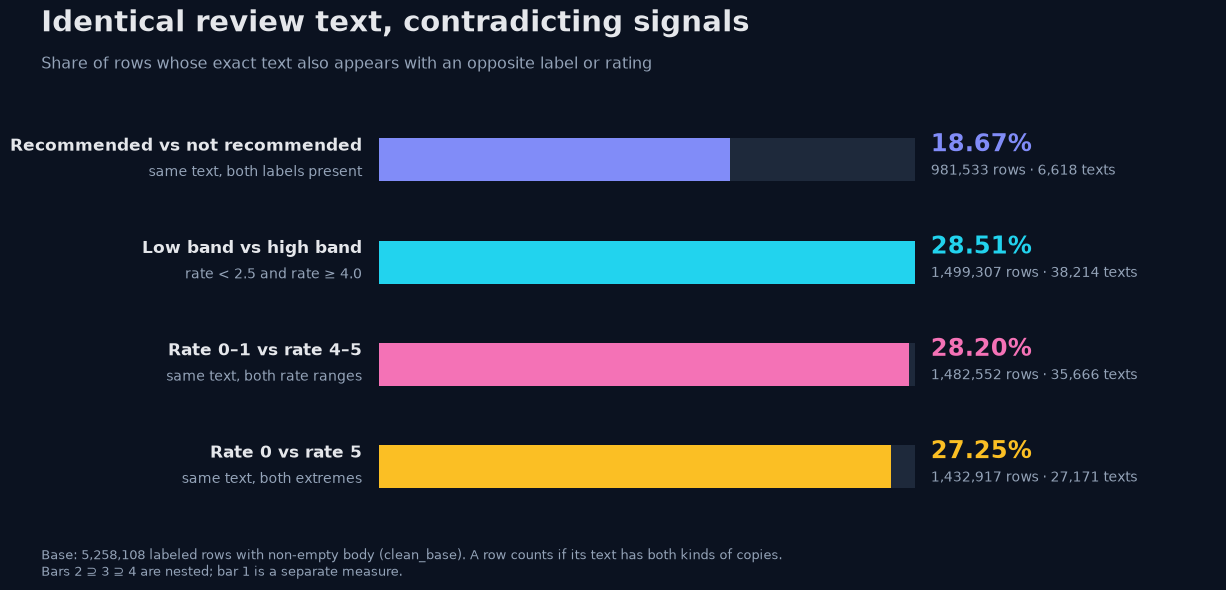

saved: /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/reports/figures/identical_text_label_conflicts.png


In [44]:
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt

# ---------- Shared theme (cell 2 reuses these names, so run this cell first) ----------
BG, TRACK = "#0B1220", "#1E293B"
TXT, MUTED = "#E5E7EB", "#94A3B8"
ACCENT = ["#818CF8", "#22D3EE", "#F472B6", "#FBBF24"]

mpl.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "text.color": TXT, "font.family": "sans-serif",
    "font.sans-serif": ["Inter", "Segoe UI", "Helvetica Neue", "Arial", "DejaVu Sans"],
})

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def fmt_pct(p):
    return f"{p:.2f}%" if p >= 0.1 else f"{p:.3f}%"

# ---------- Per-body statistics (labeled rows, non-empty body) ----------
con.execute("""
    CREATE OR REPLACE TEMP TABLE body_stats AS
    SELECT body,
           COUNT(*)                                                          AS n_rows,
           COUNT(*) FILTER (WHERE recommendation_status = 'recommended')     AS n_rec,
           COUNT(*) FILTER (WHERE recommendation_status = 'not_recommended') AS n_not,
           COUNT(*) FILTER (WHERE rate < 2.5)                                AS n_low,
           COUNT(*) FILTER (WHERE rate >= 4.0)                               AS n_high,
           COUNT(*) FILTER (WHERE rate <= 1.0)                               AS n_r01,
           COUNT(*) FILTER (WHERE rate = 0)                                  AS n_r0,
           COUNT(*) FILTER (WHERE rate = 5)                                  AS n_r5
    FROM clean_base
    WHERE body IS NOT NULL AND trim(body) <> '' AND recommendation_status IS NOT NULL
    GROUP BY body
""")
labeled = int(con.execute("SELECT SUM(n_rows) FROM body_stats").fetchall()[0][0])

CHECKS = [
    ("Recommended vs not recommended", "same text, both labels present", "n_rec > 0 AND n_not > 0"),
    ("Low band vs high band",          "rate < 2.5 and rate ≥ 4.0",       "n_low > 0 AND n_high > 0"),
    ("Rate 0–1 vs rate 4–5",           "same text, both rate ranges",     "n_r01 > 0 AND n_high > 0"),
    ("Rate 0 vs rate 5",               "same text, both extremes",        "n_r0 > 0 AND n_r5 > 0"),
]
results = []
for title, sub, cond in CHECKS:
    rows, texts = con.execute(
        f"SELECT COALESCE(SUM(n_rows), 0), COUNT(*) FROM body_stats WHERE {cond}").fetchall()[0]
    results.append(dict(title=title, sub=sub, rows=int(rows), texts=int(texts),
                        pct=100 * int(rows) / labeled))

print(f"Base: {labeled:,} labeled rows with non-empty body")
for r in results:
    print(f"{r['title']:<34} {fmt_pct(r['pct']):>8}   {r['rows']:>10,} rows   {r['texts']:>8,} distinct texts")

# ---------- Figure ----------
n = len(results)
pcts = [r["pct"] for r in results]
xmax = max(pcts)

fig, ax = plt.subplots(figsize=(12.5, 6.2))
fig.subplots_adjust(left=0.30, right=0.97, top=0.80, bottom=0.14)

ypos = list(range(n))
ax.barh(ypos, [xmax] * n, height=0.42, color=TRACK)          # background track
ax.barh(ypos, pcts, height=0.42, color=ACCENT[:n])           # actual value
ax.set_xlim(0, xmax / 0.64)
ax.set_ylim(n - 0.5, -0.5)                                   # first item on top
ax.set_xticks([]); ax.set_yticks([])
for s in ax.spines.values():
    s.set_visible(False)

ytr = ax.get_yaxis_transform()
for i, r in enumerate(results):
    ax.text(-0.02, i - 0.05, r["title"], transform=ytr, ha="right", va="bottom",
            fontsize=12.5, fontweight="bold", color=TXT)
    ax.text(-0.02, i + 0.05, r["sub"], transform=ytr, ha="right", va="top",
            fontsize=10, color=MUTED)
    ax.text(xmax * 1.03, i - 0.03, fmt_pct(r["pct"]), ha="left", va="bottom",
            fontsize=17, fontweight="bold", color=ACCENT[i])
    ax.text(xmax * 1.03, i + 0.04, f"{r['rows']:,} rows · {r['texts']:,} texts",
            ha="left", va="top", fontsize=10, color=MUTED)

fig.text(0.03, 0.925, "Identical review text, contradicting signals", fontsize=21, fontweight="bold")
fig.text(0.03, 0.865, "Share of rows whose exact text also appears with an opposite label or rating",
         fontsize=11.5, color=MUTED)
fig.text(0.03, 0.04,
         f"Base: {labeled:,} labeled rows with non-empty body (clean_base). A row counts if its text has "
         "both kinds of copies.\nBars 2 ⊇ 3 ⊇ 4 are nested; bar 1 is a separate measure.",
         fontsize=9, color=MUTED, va="bottom")

out1 = FIG_DIR / "identical_text_label_conflicts.png"
fig.savefig(out1, dpi=200)
plt.show()
print("saved:", out1)

# What percentage of rows have exactly the same text?

clean_base rows: 6,151,947  |  rows with non-empty body: 6,151,947  (empty/NULL body: 0)
unique text   : 3,807,535 rows (61.89%)
repeated text : 2,344,412 rows (38.11%)
  Appears 2×            3.05%     187,356 rows     93,678 texts
  Appears 3–5×          3.45%     212,156 rows     58,655 texts
  Appears 6–20×         4.63%     284,553 rows     29,191 texts
  Appears 21–100×       4.79%     294,739 rows      7,342 texts
  Appears 100+×        22.20%   1,365,608 rows      1,878 texts


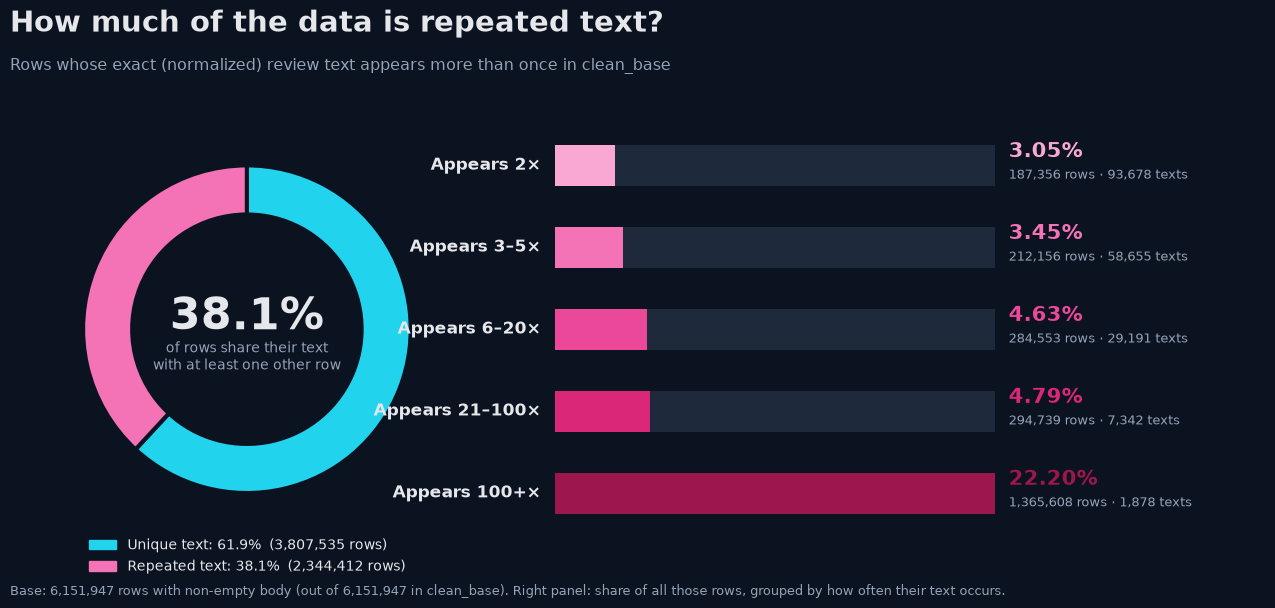

saved: /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/reports/figures/identical_text_share.png


In [45]:
from matplotlib.patches import Patch

# ---------- Statistics: how often does each exact text appear? ----------
con.execute("""
    CREATE OR REPLACE TEMP TABLE body_counts AS
    SELECT body, COUNT(*) AS n
    FROM clean_base
    WHERE body IS NOT NULL AND trim(body) <> ''
    GROUP BY body
""")
n_all  = con.execute("SELECT COUNT(*) FROM clean_base").fetchall()[0][0]
tot    = int(con.execute("SELECT SUM(n) FROM body_counts").fetchall()[0][0])

rows = con.execute("""
    SELECT CASE WHEN n = 1 THEN '1'  WHEN n = 2 THEN '2'  WHEN n <= 5  THEN '3-5'
                WHEN n <= 20 THEN '6-20' WHEN n <= 100 THEN '21-100' ELSE '>100' END AS bucket,
           COUNT(*) AS n_texts, SUM(n) AS n_rows
    FROM body_counts GROUP BY 1
""").fetchall()
stat = {b: (int(t), int(r)) for b, t, r in rows}

unique_rows   = stat.get("1", (0, 0))[1]
repeated_rows = tot - unique_rows
rep_pct = 100 * repeated_rows / tot

print(f"clean_base rows: {n_all:,}  |  rows with non-empty body: {tot:,}  (empty/NULL body: {n_all - tot:,})")
print(f"unique text   : {unique_rows:,} rows ({100 * unique_rows / tot:.2f}%)")
print(f"repeated text : {repeated_rows:,} rows ({rep_pct:.2f}%)")

order  = ["2", "3-5", "6-20", "21-100", ">100"]
labels = {"2": "Appears 2×", "3-5": "Appears 3–5×", "6-20": "Appears 6–20×",
          "21-100": "Appears 21–100×", ">100": "Appears 100+×"}
bar_rows  = [stat.get(b, (0, 0))[1] for b in order]
bar_texts = [stat.get(b, (0, 0))[0] for b in order]
bar_pcts  = [100 * r / tot for r in bar_rows]
for b, r, t, p in zip(order, bar_rows, bar_texts, bar_pcts):
    print(f"  {labels[b]:<18} {fmt_pct(p):>8}  {r:>10,} rows  {t:>9,} texts")

# ---------- Figure ----------
PINKS = ["#F9A8D4", "#F472B6", "#EC4899", "#DB2777", "#9D174D"]

fig = plt.figure(figsize=(13.5, 6.4))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.5], left=0.04, right=0.97, top=0.78, bottom=0.14, wspace=0.12)
ax1, ax2 = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])

# Left: donut (unique vs repeated)
ax1.pie([unique_rows, repeated_rows], colors=[ACCENT[1], ACCENT[2]], startangle=90,
        counterclock=False, wedgeprops=dict(width=0.30, edgecolor=BG, linewidth=3))
ax1.text(0, 0.07, f"{rep_pct:.1f}%", ha="center", va="center", fontsize=32, fontweight="bold")
ax1.text(0, -0.17, "of rows share their text\nwith at least one other row",
         ha="center", va="center", fontsize=10, color=MUTED)
ax1.legend(handles=[Patch(color=ACCENT[1], label=f"Unique text: {100 * unique_rows / tot:.1f}%  ({unique_rows:,} rows)"),
                    Patch(color=ACCENT[2], label=f"Repeated text: {rep_pct:.1f}%  ({repeated_rows:,} rows)")],
           loc="upper center", bbox_to_anchor=(0.5, 0.02), frameon=False, labelcolor=TXT, fontsize=10)

# Right: repeated rows by repetition level (share of ALL rows with a body)
m = max(bar_pcts) if max(bar_pcts) > 0 else 1
ax2.barh(range(len(order)), [m] * len(order), height=0.5, color=TRACK)
ax2.barh(range(len(order)), bar_pcts, height=0.5, color=PINKS)
ax2.set_xlim(0, m / 0.62)
ax2.set_ylim(len(order) - 0.5, -0.5)
ax2.set_xticks([]); ax2.set_yticks([])
for s in ax2.spines.values():
    s.set_visible(False)
tr2 = ax2.get_yaxis_transform()
for i, b in enumerate(order):
    ax2.text(-0.02, i, labels[b], transform=tr2, ha="right", va="center", fontsize=12, fontweight="bold")
    ax2.text(m * 1.03, i - 0.04, fmt_pct(bar_pcts[i]), ha="left", va="bottom",
             fontsize=15, fontweight="bold", color=PINKS[i])
    ax2.text(m * 1.03, i + 0.04, f"{bar_rows[i]:,} rows · {bar_texts[i]:,} texts",
             ha="left", va="top", fontsize=9.5, color=MUTED)

fig.text(0.04, 0.925, "How much of the data is repeated text?", fontsize=21, fontweight="bold")
fig.text(0.04, 0.865, "Rows whose exact (normalized) review text appears more than once in clean_base",
         fontsize=11.5, color=MUTED)
fig.text(0.04, 0.04,
         f"Base: {tot:,} rows with non-empty body (out of {n_all:,} in clean_base). "
         "Right panel: share of all those rows, grouped by how often their text occurs.",
         fontsize=9, color=MUTED, va="bottom")

out2 = FIG_DIR / "identical_text_share.png"
fig.savefig(out2, dpi=200)
plt.show()
print("saved:", out2)

## let's see the frequent and contradict texts:

In [52]:
EX_DIR = ROOT / "reports" / "examples"
(EX_DIR / "conflicts").mkdir(parents=True, exist_ok=True)
(EX_DIR / "repetition").mkdir(parents=True, exist_ok=True)

def save_csv(sql, path):
    df = con.execute(sql).df()
    df.to_csv(path, index=False, encoding="utf-8-sig")   # BOM so Excel shows Persian correctly
    return df

# ---------- A) Conflict examples (one CSV per comparison in the first figure) ----------
conf_dir = EX_DIR / "conflicts"

# 01: recommended vs not_recommended  ->  sort by n_rec + n_not
df01 = save_csv("""
    SELECT body, n_rows, n_rec, n_not, n_low, n_high, n_r01, n_r0, n_r5
    FROM body_stats
    WHERE n_rec > 0 AND n_not > 0
    ORDER BY (n_rec + n_not) DESC, LEAST(n_rec, n_not) DESC, body
    LIMIT 100
""", conf_dir / "01_recommended_vs_not_recommended.csv")

# 02: low band vs high band  ->  sort by n_low + n_high
df02 = save_csv("""
    SELECT body, n_rows, n_rec, n_not, n_low, n_high, n_r01, n_r0, n_r5
    FROM body_stats
    WHERE n_low > 0 AND n_high > 0
    ORDER BY (n_low + n_high) DESC, LEAST(n_low, n_high) DESC, body
    LIMIT 100
""", conf_dir / "02_low_band_vs_high_band.csv")

# 03: rate 0-1 vs rate 4-5  ->  sort by n_r01 + n_high
df03 = save_csv("""
    SELECT body, n_rows, n_rec, n_not, n_low, n_high, n_r01, n_r0, n_r5
    FROM body_stats
    WHERE n_r01 > 0 AND n_high > 0
    ORDER BY (n_r01 + n_high) DESC, LEAST(n_r01, n_high) DESC, body
    LIMIT 100
""", conf_dir / "03_rate_0-1_vs_rate_4-5.csv")

# 04: rate 0 vs rate 5  ->  sort by n_r0 + n_r5
df04 = save_csv("""
    SELECT body, n_rows, n_rec, n_not, n_low, n_high, n_r01, n_r0, n_r5
    FROM body_stats
    WHERE n_r0 > 0 AND n_r5 > 0
    ORDER BY (n_r0 + n_r5) DESC, LEAST(n_r0, n_r5) DESC, body
    LIMIT 100
""", conf_dir / "04_rate_0_vs_rate_5.csv")

for name, d in [("01", df01), ("02", df02), ("03", df03), ("04", df04)]:
    print(f"{name}: {len(d)} rows saved")

# Quick look at the top of table 04
print(df04[["body", "n_rows", "n_r0", "n_r5"]].head(10).to_string(index=False))
# ---------- B) Repetition examples (one CSV per repetition level in the second figure) ----------
buckets = [("appears_2x", "n = 2"), ("appears_3_5x", "n BETWEEN 3 AND 5"),
           ("appears_6_20x", "n BETWEEN 6 AND 20"), ("appears_21_100x", "n BETWEEN 21 AND 100"),
           ("appears_100plus", "n > 100")]
for name, cond in buckets:
    df = save_csv(f"""
        SELECT n AS times_repeated, body
        FROM body_counts
        WHERE {cond}
        ORDER BY hash(body)
        LIMIT 100
    """, EX_DIR / "repetition" / f"{name}.csv")
    print(f"{name}.csv  ({len(df)} examples)")

# Extra: the 100 most frequent texts overall (they live in the 100+ bucket)
top = save_csv("""
    SELECT n AS times_repeated, body FROM body_counts ORDER BY n DESC LIMIT 100
""", EX_DIR / "repetition" / "top_100_most_frequent_texts.csv")

print("\nTop 100 most frequent texts:")
for _, r in top.iterrows():
    print(f"  {int(r.times_repeated):>9,}×  {r.body[:70]}")
print("\nsaved under:", EX_DIR)

01: 100 rows saved
02: 100 rows saved
03: 100 rows saved
04: 100 rows saved
         body  n_rows  n_r0  n_r5
         عالی   96974  2721 79806
      خوب بود   68986  7011 20100
         خوبه   61598  1156 20827
     عالی بود   23246  2877 15905
          خوب   49211  1040 15758
        عالیه   18291  1939 12849
 خیلی خوب بود   15529  1026 10469
        عالیی   11716   931  9075
پیشنهاد میکنم   13817  1389  7446
    خیلی خوبه   10111   939  6340
appears_2x.csv  (100 examples)
appears_3_5x.csv  (100 examples)
appears_6_20x.csv  (100 examples)
appears_21_100x.csv  (100 examples)
appears_100plus.csv  (100 examples)

Top 100 most frequent texts:
    137,065×  عالی
     90,534×  خوب بود
     83,945×  خوبه
     70,813×  خوب
     31,175×  عالی بود
     23,959×  عالیه
     17,802×  خیلی خوب بود
     15,632×  پیشنهاد میکنم
     15,421×  معمولی
     14,386×  عالیی
     12,821×  خیلی خوبه
     10,151×  بسیار عالی
     10,021×  بد نیست
      9,661×  نسبت به قیمتش خوبه
      8,872×  قیمت مناسب
    

# Comments lenght and word count

reviews: 6,151,947
median 6 | mean 10.1 | p90 22 | p95 32 | p99 62 | max 908 words
most common length: 3 words (10.62%) | <=3 words: 27.32% | >70 words: 0.69%


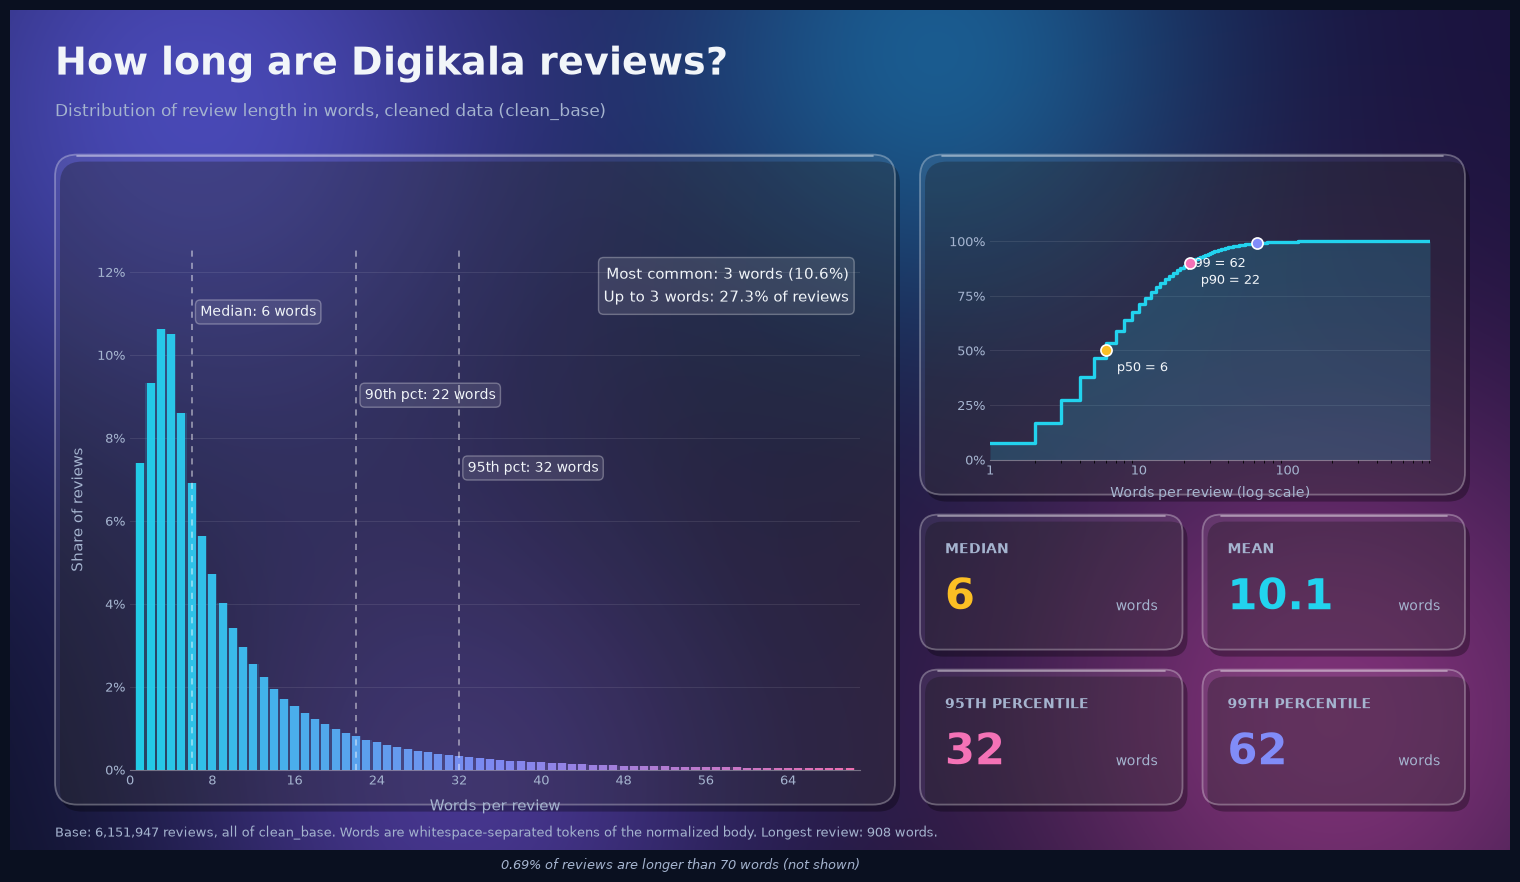

saved: /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/reports/figures/review_length_distribution.png


In [53]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, NullFormatter, MaxNLocator
from pathlib import Path

# ---------- 1) Word counts per review (computed in DuckDB, full clean_base) ----------
con.execute(r"""
    CREATE OR REPLACE TEMP TABLE wc_counts AS
    SELECT len(string_split_regex(trim(body), '\s+')) AS words, COUNT(*) AS n
    FROM clean_base
    WHERE body IS NOT NULL AND trim(body) <> ''
    GROUP BY 1
""")
df = con.execute("SELECT words, n FROM wc_counts ORDER BY words").df()
total = int(df.n.sum())
cum = df.n.cumsum() / total

def wq(q):                                   # weighted quantile (in words)
    return int(df.words[cum >= q].iloc[0])

median, p90, p95, p99 = wq(0.50), wq(0.90), wq(0.95), wq(0.99)
mean_w   = float((df.words * df.n).sum() / total)
max_w    = int(df.words.max())
mode_w   = int(df.words[df.n.idxmax()])
mode_pct = 100 * int(df.n.max()) / total
short_pct = 100 * int(df.n[df.words <= 3].sum()) / total

CAP = int(np.clip(np.ceil(p99 / 10) * 10, 40, 150))
over_cap_pct = 100 * int(df.n[df.words > CAP].sum()) / total

print(f"reviews: {total:,}")
print(f"median {median} | mean {mean_w:.1f} | p90 {p90} | p95 {p95} | p99 {p99} | max {max_w:,} words")
print(f"most common length: {mode_w} words ({mode_pct:.2f}%) | <=3 words: {short_pct:.2f}% | >{CAP} words: {over_cap_pct:.2f}%")

# ---------- 2) Theme + glass helpers ----------
TXT, MUTED = "#F1F5F9", "#A5B4CF"
W, H = 15.0, 8.4                              # figure size in inches (also the coordinate system)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "reports" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)

def background(h_px=420, w_px=760):
    """Dark gradient with soft colored glows, so the glass cards have something to 'refract'."""
    yy, xx = np.mgrid[0:h_px, 0:w_px]
    x, y = xx / w_px, 1 - yy / h_px
    base = np.array([0.04, 0.06, 0.14]) + (np.array([0.10, 0.07, 0.24]) - np.array([0.04, 0.06, 0.14])) * ((x + y) / 2)[..., None]
    img = base.copy()
    for cx, cy, r, col, a in [(0.12, 0.88, 0.30, "#6366F1", 0.55), (0.88, 0.15, 0.28, "#EC4899", 0.45),
                              (0.62, 0.95, 0.22, "#06B6D4", 0.40), (0.30, 0.05, 0.25, "#8B5CF6", 0.40)]:
        g = np.exp(-((x - cx) ** 2 + ((y - cy) * 0.55) ** 2) / (2 * r ** 2 * 0.35))
        img += g[..., None] * a * np.array(mpl.colors.to_rgb(col))
    return np.clip(img, 0, 1)

def glass(ax, x, y, w, h, r=0.22):
    st = f"round,pad=0,rounding_size={r}"
    ax.add_patch(FancyBboxPatch((x + 0.05, y - 0.07), w, h, boxstyle=st, fc=(0, 0, 0, 0.30), ec="none", zorder=1))      # shadow
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle=st, fc=(1, 1, 1, 0.075), ec=(1, 1, 1, 0.30), lw=1.3, zorder=2))  # glass
    ax.plot([x + r, x + w - r], [y + h - 0.012] * 2, color=(1, 1, 1, 0.45), lw=1.2, zorder=3, solid_capstyle="round")   # shine

def glass_axes(fig, x, y, w, h, pad=(0.75, 0.35, 0.35, 0.95)):
    l, b, r_, t = pad                          # padding inside the card (inches)
    ax = fig.add_axes([(x + l) / W, (y + b) / H, (w - l - r_) / W, (h - b - t) / H])
    ax.set_facecolor("none"); ax.set_zorder(5)
    for s in ["top", "right", "left"]:
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color((1, 1, 1, 0.35))
    ax.tick_params(colors=MUTED, labelsize=9.5, length=0)
    ax.grid(axis="y", color=(1, 1, 1, 0.09), lw=0.8); ax.set_axisbelow(True)
    return ax

fig = plt.figure(figsize=(W, H), facecolor="#0A1020")
bg = fig.add_axes([0, 0, 1, 1]); bg.set_xlim(0, W); bg.set_ylim(0, H); bg.axis("off")
bg.imshow(background(), extent=[0, W, 0, H], aspect="auto", zorder=0)

# layout (inches)
M, top = 0.45, 1.45
cx0, cw = M, 8.4                               # left card (histogram)
rx0, rw = cx0 + cw + 0.25, W - (cx0 + cw + 0.25) - M
ch = H - M - top                               # content height
tile_h, gap = 1.35, 0.2
cdf_y = M + 2 * tile_h + gap + 0.2

glass(bg, cx0, M, cw, ch)
glass(bg, rx0, cdf_y, rw, M + ch - cdf_y)

# ---------- 3) Main panel: histogram (% of reviews per word count) ----------
cmap = LinearSegmentedColormap.from_list("len", ["#22D3EE", "#818CF8", "#F472B6"])
xs = np.arange(1, CAP + 1)
ys = df.set_index("words").n.reindex(xs, fill_value=0).values / total * 100
cols = cmap((xs - 1) / (CAP - 1))

axh = glass_axes(fig, cx0, M, cw, ch)
axh.bar(xs, ys, width=1.0, color=cols, alpha=0.18, lw=0)         # soft glow underneath
axh.bar(xs, ys, width=0.78, color=cols, alpha=0.95, lw=0)
axh.set_xlim(0, CAP + 1); axh.set_ylim(0, ys.max() * 1.18)
axh.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=10))
axh.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
axh.set_xlabel("Words per review", color=MUTED, fontsize=11, labelpad=8)
axh.set_ylabel("Share of reviews", color=MUTED, fontsize=11, labelpad=8)

pill = dict(boxstyle="round,pad=0.35", fc=(1, 1, 1, 0.10), ec=(1, 1, 1, 0.30), lw=1)
for val, lab, ypos in [(median, "Median", 0.88), (p90, "90th pct", 0.72), (p95, "95th pct", 0.58)]:
    if val <= CAP:
        axh.axvline(val, color=(1, 1, 1, 0.55), ls=(0, (4, 4)), lw=1.1)
        axh.text(val + CAP * 0.012, axh.get_ylim()[1] * ypos, f"{lab}: {val} words",
                 color=TXT, fontsize=10, va="center", bbox=pill)
axh.text(0.985, 0.975,
         f"Most common: {mode_w} word{'s' if mode_w != 1 else ''} ({mode_pct:.1f}%)\n"
         f"Up to 3 words: {short_pct:.1f}% of reviews",
         transform=axh.transAxes, ha="right", va="top", color=TXT, fontsize=10.5, linespacing=1.6, bbox=pill)
axh.text(1.0, -0.17, f"{over_cap_pct:.2f}% of reviews are longer than {CAP} words (not shown)",
         transform=axh.transAxes, ha="right", va="top", color=MUTED, fontsize=9, style="italic")

# ---------- 4) Side panel: cumulative share (log x) ----------
axc = glass_axes(fig, rx0, cdf_y, rw, M + ch - cdf_y, pad=(0.7, 0.35, 0.35, 0.8))
axc.fill_between(df.words, cum * 100, step="post", color="#22D3EE", alpha=0.18, lw=0)
axc.step(df.words, cum * 100, where="post", color="#22D3EE", lw=2.4)
axc.set_xscale("log"); axc.set_xlim(1, max_w); axc.set_ylim(0, 103)
axc.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}")); axc.xaxis.set_minor_formatter(NullFormatter())
axc.set_yticks([0, 25, 50, 75, 100]); axc.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
axc.set_xlabel("Words per review (log scale)", color=MUTED, fontsize=10, labelpad=6)
for val, q, col, off, ha in [(median, 50, "#FBBF24", (8, -15), "left"), (p90, 90, "#F472B6", (8, -15), "left"),
                             (p99, 99, "#818CF8", (-8, -17), "right")]:
    axc.plot(val, q, "o", ms=8, color=col, mec="white", mew=1.2, zorder=6)
    axc.annotate(f"p{q} = {val}", (val, q), xytext=off, textcoords="offset points",
                 color=TXT, fontsize=9.5, ha=ha)

# ---------- 5) KPI tiles ----------
tw = (rw - gap) / 2
tiles = [("MEDIAN", f"{median:,}", "#FBBF24"), ("MEAN", f"{mean_w:.1f}", "#22D3EE"),
         ("95TH PERCENTILE", f"{p95:,}", "#F472B6"), ("99TH PERCENTILE", f"{p99:,}", "#818CF8")]
for i, (lab, val, col) in enumerate(tiles):
    tx = rx0 + (i % 2) * (tw + gap)
    ty = M + (1 - i // 2) * (tile_h + gap)
    glass(bg, tx, ty, tw, tile_h, r=0.18)
    bg.text(tx + 0.25, ty + tile_h - 0.28, lab, color=MUTED, fontsize=10, va="top", fontweight="bold", zorder=6)
    bg.text(tx + 0.25, ty + 0.30, val, color=col, fontsize=31, fontweight="bold", va="bottom", zorder=6)
    bg.text(tx + tw - 0.25, ty + 0.36, "words", color=MUTED, fontsize=10, ha="right", va="bottom", zorder=6)

# ---------- 6) Title + footer ----------
bg.text(M, H - 0.55, "How long are Digikala reviews?", color=TXT, fontsize=27, fontweight="bold", va="center", zorder=6)
bg.text(M, H - 1.02, "Distribution of review length in words, cleaned data (clean_base)",
        color=MUTED, fontsize=12.5, va="center", zorder=6)
bg.text(M, 0.17, f"Base: {total:,} reviews, all of clean_base. Words are whitespace-separated tokens of the normalized body. "
                 f"Longest review: {max_w:,} words.", color=MUTED, fontsize=9, va="center", zorder=6)

out = FIG_DIR / "review_length_distribution.png"
fig.savefig(out, dpi=200, facecolor=fig.get_facecolor())
plt.show()
print("saved:", out)

---